# PHASE 1

In [1]:

# STEP 1: INSTALL REQUIRED LIBRARIES

%pip install -q pandas numpy matplotlib seaborn scikit-learn statsmodels prophet holidays openpyxl

print("Library installation command completed!")



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Library installation command completed!


In [2]:

# STEP 2: VERIFY LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import statsmodels
from prophet import Prophet

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Prophet is ready!")


All libraries imported successfully!
Pandas version: 2.2.3
NumPy version: 2.4.6
Prophet is ready!


In [3]:

# STEP 3: ENVIRONMENT VERIFICATION

print("Python environment is ready.")

print("\nLibrary versions:")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Statsmodels:", statsmodels.__version__)

print("\nCurrent working directory:")
print(os.getcwd())

print("\nEnvironment verification completed!")


Python environment is ready.

Library versions:
Pandas: 2.2.3
NumPy: 2.4.6
Scikit-learn: 1.6.1
Statsmodels: 0.15.0

Current working directory:
/datasets/_deepnote_work

Environment verification completed!


In [4]:

# STEP 4: GENERATE SYNTHETIC HOSPITAL DATA

# Total records
N = 500_000

# Reproducible random generator
rng = np.random.default_rng(42)

# Four fictional hospitals
hospitals = [
    "Pune Central Hospital",
    "Shivaji Nagar Hospital",
    "Hadapsar Community Hospital",
    "Kothrud Community Hospital"
]

hospital_weights = [0.32, 0.27, 0.23, 0.18]

# Medical departments
departments = [
    "General Medicine",
    "Cardiology",
    "Orthopedics",
    "Pediatrics",
    "Neurology",
    "Emergency",
    "Gynecology"
]

department_weights = [0.28, 0.12, 0.13, 0.14, 0.10, 0.15, 0.08]

# Historical date range
start_date = "2023-01-01"
end_date = "2026-10-31"

all_dates = pd.date_range(
    start=start_date,
    end=end_date,
    freq="D"
)

# Annual seasonal pattern
day_number = np.arange(len(all_dates))

annual_seasonality = (
    1 + 0.15 * np.sin(2 * np.pi * day_number / 365.25)
)

# Long-term demand growth
long_term_trend = 1 + 0.00012 * day_number

# Weekday patterns
weekday_weights = np.array([
    1.05, 1.10, 1.10, 1.10, 1.10, 0.90, 0.70
])

weekday_effect = weekday_weights[all_dates.dayofweek]

# Simulated festival dates
festival_dates = [
    "2023-03-08", "2023-11-12",
    "2024-03-25", "2024-11-01",
    "2025-03-14", "2025-10-20",
    "2026-03-04", "2026-11-08"
]

festival_effect = np.ones(len(all_dates))

for festival in festival_dates:
    festival_date = pd.Timestamp(festival)

    distance = np.abs(
        (all_dates - festival_date).days
    )

    festival_effect[distance <= 2] *= 0.85

# Calculate date sampling probabilities
date_weights = (
    annual_seasonality *
    long_term_trend *
    weekday_effect *
    festival_effect
)

date_probabilities = date_weights / date_weights.sum()

# Generate visit dates
visit_dates = pd.to_datetime(
    rng.choice(
        all_dates.to_numpy(),
        size=N,
        p=date_probabilities
    )
)

# Generate hospital information
hospital_data = rng.choice(
    hospitals,
    size=N,
    p=hospital_weights
)

department_data = rng.choice(
    departments,
    size=N,
    p=department_weights
)

# Generate patient visit types
visit_types = rng.choice(
    ["OPD", "Admission"],
    size=N,
    p=[0.88, 0.12]
)

# Patient ages
patient_ages = rng.integers(1, 91, size=N)

# Patient identifiers
patient_ids = [
    f"PAT{i:07d}"
    for i in rng.integers(1, 150001, size=N)
]

# Laboratory tests
lab_tests = rng.poisson(
    np.where(visit_types == "Admission", 5, 2)
)

# Billing amounts
billing_amounts = np.where(
    visit_types == "Admission",
    rng.gamma(5, 3500, size=N),
    rng.gamma(2.5, 700, size=N)
)

billing_amounts = np.round(billing_amounts, 2)

# Diagnosis categories
diagnosis_codes = rng.choice(
    ["D001", "D002", "D003", "D004", "D005", "D006"],
    size=N
)

# Simulated length of stay
length_of_stay = np.where(
    visit_types == "Admission",
    rng.integers(1, 15, size=N),
    0
)

discharge_dates = (
    visit_dates +
    pd.to_timedelta(length_of_stay, unit="D")
)

# Create the DataFrame
df = pd.DataFrame({
    "record_id": np.arange(1, N + 1),
    "patient_id": patient_ids,
    "hospital": hospital_data,
    "visit_date": visit_dates,
    "department": department_data,
    "visit_type": visit_types,
    "patient_age": patient_ages.astype(object),
    "lab_tests": lab_tests,
    "billing_amount": billing_amounts,
    "diagnosis_code": diagnosis_codes,
    "length_of_stay": length_of_stay,
    "discharge_date": discharge_dates
})

print("Synthetic hospital dataset generated!")
print("Total records:", len(df))
print("Total columns:", len(df.columns))


Synthetic hospital dataset generated!
Total records: 500000
Total columns: 12


In [5]:

# STEP 5: INTRODUCE DATA QUALITY ISSUES

# 1. Missing patient ages
missing_age = rng.choice(
    df.index,
    size=10000,
    replace=False
)

df.loc[missing_age, "patient_age"] = np.nan

# 2. Incorrectly entered dates of birth
valid_age_rows = df.index[
    df["patient_age"].notna()
]

dob_rows = rng.choice(
    valid_age_rows,
    size=5000,
    replace=False
)

dob_values = (
    df.loc[dob_rows, "visit_date"] -
    pd.to_timedelta(
        df.loc[dob_rows, "patient_age"].astype(int) * 365.25,
        unit="D"
    )
)

df.loc[dob_rows, "patient_age"] = (
    dob_values.dt.strftime("%Y-%m-%d").values
)

# 3. Missing laboratory test values
missing_lab = rng.choice(
    df.index,
    size=3000,
    replace=False
)

df.loc[missing_lab, "lab_tests"] = np.nan

# 4. Missing billing values
missing_billing = rng.choice(
    df.index,
    size=2000,
    replace=False
)

df.loc[missing_billing, "billing_amount"] = np.nan

# 5. Missing visit dates
missing_dates = rng.choice(
    df.index,
    size=500,
    replace=False
)

df.loc[missing_dates, "visit_date"] = pd.NaT

# 6. Missing discharge dates for some admissions
admission_rows = df.index[
    df["visit_type"] == "Admission"
]

missing_discharge = rng.choice(
    admission_rows,
    size=int(len(admission_rows) * 0.08),
    replace=False
)

df.loc[missing_discharge, "discharge_date"] = pd.NaT

print("Data-quality issues introduced successfully!")
print("Missing ages:", df["patient_age"].isna().sum())
print("Missing lab tests:", df["lab_tests"].isna().sum())
print("Missing billing:", df["billing_amount"].isna().sum())
print("Missing visit dates:", df["visit_date"].isna().sum())
print("Missing discharge dates:", df["discharge_date"].isna().sum())


Data-quality issues introduced successfully!
Missing ages: 10000
Missing lab tests: 3000
Missing billing: 2000
Missing visit dates: 500
Missing discharge dates: 4817


In [6]:

# STEP 6: DATASET INSPECTION

print("=" * 55)
print("HOSPITAL DATASET OVERVIEW")
print("=" * 55)

print("\n1. DATASET DIMENSIONS")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\n2. FIRST 10 RECORDS")
display(df.head(10))

print("\n3. LAST 5 RECORDS")
display(df.tail())

print("\n4. COLUMN DATA TYPES")
display(df.dtypes.to_frame("Data Type"))

print("\n5. HOSPITAL-WISE RECORD COUNTS")
display(df["hospital"].value_counts())

print("\n6. DEPARTMENT-WISE RECORD COUNTS")
display(df["department"].value_counts())

print("\n7. VISIT TYPE DISTRIBUTION")
display(df["visit_type"].value_counts())

print("\n8. MISSING VALUE SUMMARY")
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

display(missing_summary)

print("\n9. DATE RANGE")
print("Start:", df["visit_date"].min())
print("End:", df["visit_date"].max())

print("\n10. STATISTICAL SUMMARY")
display(df.describe(include="all").T)


HOSPITAL DATASET OVERVIEW

1. DATASET DIMENSIONS
Rows: 500000
Columns: 12

2. FIRST 10 RECORDS


,record_id,patient_id,hospital,visit_date,department,visit_type,patient_age,lab_tests,billing_amount,diagnosis_code,length_of_stay,discharge_date
0,1,PAT0134487,Shivaji Nagar Hospital,2026-01-10,Neurology,OPD,30,2.0,1855.45,D005,0,2026-01-10
1,2,PAT0030038,Pune Central Hospital,2024-09-25,Orthopedics,OPD,75,4.0,838.68,D005,0,2024-09-25
2,3,PAT0144663,Kothrud Community Hospital,2026-04-22,General Medicine,OPD,45,1.0,2144.82,D004,0,2026-04-22
3,4,PAT0076778,Shivaji Nagar Hospital,2025-09-18,Cardiology,OPD,88,2.0,2151.45,D001,0,2025-09-18
4,5,PAT0020454,Hadapsar Community Hospital,2023-05-09,Pediatrics,Admission,20,8.0,16143.25,D001,7,2023-05-16
5,6,PAT0046149,Shivaji Nagar Hospital,2026-09-24,General Medicine,OPD,55,2.0,1774.60,D005,0,2026-09-24
6,7,PAT0109534,Shivaji Nagar Hospital,2025-12-24,Neurology,Admission,19,2.0,14208.97,D002,2,2025-12-26
7,8,PAT0075409,Pune Central Hospital,2026-01-26,Emergency,OPD,68,2.0,203.69,D006,0,2026-01-26
8,9,PAT0078743,Hadapsar Community Hospital,2023-06-25,Emergency,OPD,15,2.0,2730.61,D006,0,2023-06-25
9,10,PAT0098449,Shivaji Nagar Hospital,2024-10-15,General Medicine,OPD,15,0.0,3355.30,D001,0,2024-10-15



3. LAST 5 RECORDS


,record_id,patient_id,hospital,visit_date,department,visit_type,patient_age,lab_tests,billing_amount,diagnosis_code,length_of_stay,discharge_date
499995,499996,PAT0063260,Kothrud Community Hospital,2025-12-14,General Medicine,OPD,24,5.0,1037.82,D001,0,2025-12-14
499996,499997,PAT0032507,Pune Central Hospital,2023-09-18,General Medicine,OPD,1981-09-17,2.0,2822.40,D003,0,2023-09-18
499997,499998,PAT0079927,Shivaji Nagar Hospital,2026-02-04,Pediatrics,OPD,38,1.0,2470.24,D001,0,2026-02-04
499998,499999,PAT0142908,Kothrud Community Hospital,2026-07-10,General Medicine,OPD,5,1.0,1994.95,D005,0,2026-07-10
499999,500000,PAT0042444,Hadapsar Community Hospital,2023-07-07,General Medicine,OPD,9,1.0,2722.22,D004,0,2023-07-07



4. COLUMN DATA TYPES


,Data Type
record_id,int64
patient_id,object
hospital,object
visit_date,datetime64[ns]
department,object
visit_type,object
patient_age,object
lab_tests,float64
billing_amount,float64
diagnosis_code,object


... (6 outputs left out)


8. MISSING VALUE SUMMARY


,Missing Count,Missing Percentage
record_id,0,0.00
patient_id,0,0.00
hospital,0,0.00
visit_date,500,0.10
department,0,0.00
visit_type,0,0.00
patient_age,10000,2.00
lab_tests,3000,0.60
billing_amount,2000,0.40
diagnosis_code,0,0.00



9. DATE RANGE
Start: 2023-01-01 00:00:00
End: 2026-10-31 00:00:00

10. STATISTICAL SUMMARY


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
record_id,500000.0,NaN,NaN,NaN,250000.5,1.0,125000.75,250000.5,375000.25,500000.0,144337.711635
patient_id,500000,144613,PAT0132948,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hospital,500000,4,Pune Central Hospital,159618,NaN,NaN,NaN,NaN,NaN,NaN,NaN
visit_date,499500,NaN,NaN,NaN,2024-12-11 09:38:11.113513472,2023-01-01 00:00:00,2024-01-07 00:00:00,2024-12-29 00:00:00,2025-12-08 00:00:00,2026-10-31 00:00:00,NaN
department,500000,7,General Medicine,139784,NaN,NaN,NaN,NaN,NaN,NaN,NaN
visit_type,500000,2,OPD,439776,NaN,NaN,NaN,NaN,NaN,NaN,NaN
patient_age,490000.0,4705.0,84.0,5626.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lab_tests,497000.0,NaN,NaN,NaN,2.357278,0.0,1.0,2.0,3.0,17.0,1.821314
billing_amount,498000.0,NaN,NaN,NaN,3651.154175,6.57,1014.85,1708.14,2860.8925,77232.78,5906.356155
diagnosis_code,500000,6,D003,83663,NaN,NaN,NaN,NaN,NaN,NaN,NaN


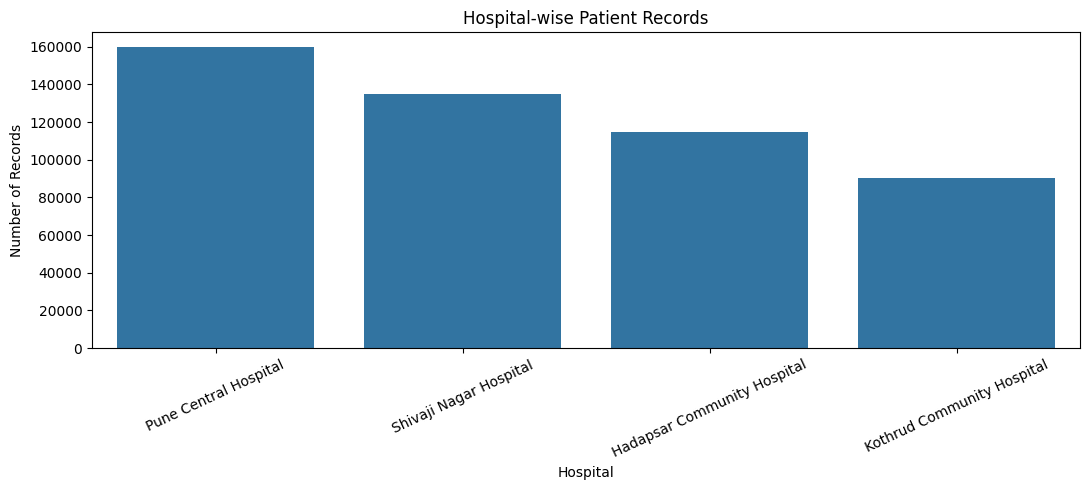

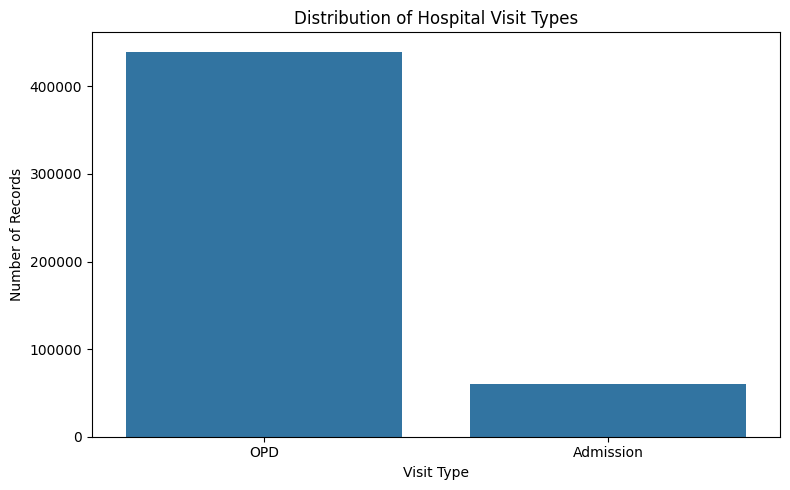

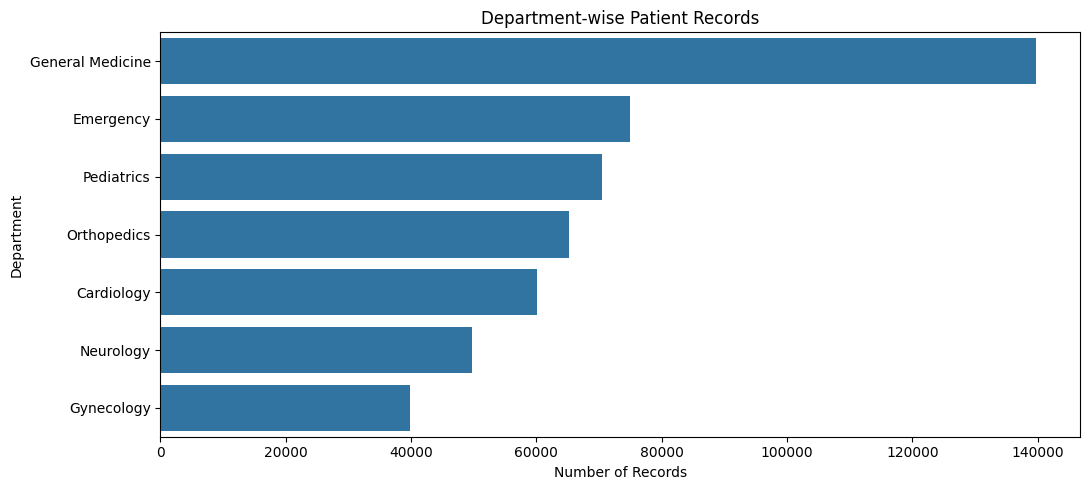

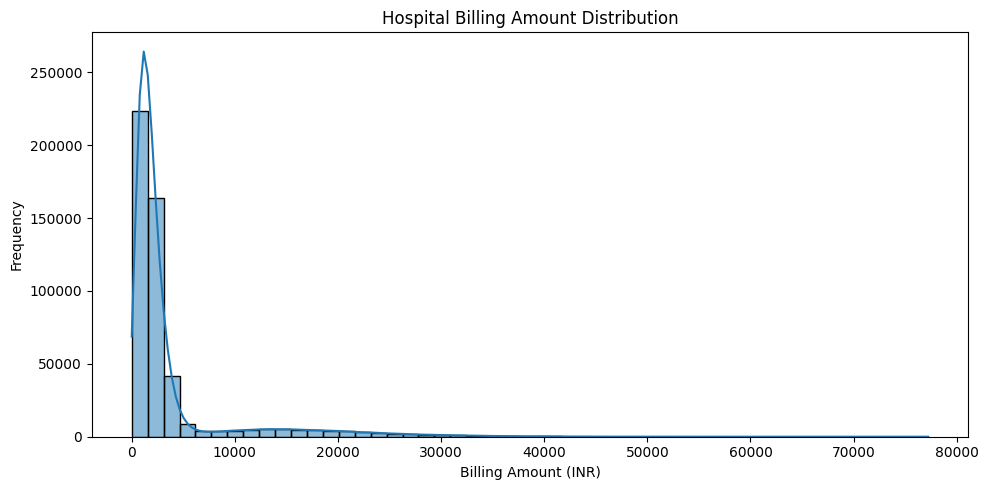

In [7]:

# STEP 7: INITIAL DATA VISUALIZATION

# Chart 1: Hospital-wise records
plt.figure(figsize=(11, 5))

sns.countplot(
    data=df,
    x="hospital",
    order=df["hospital"].value_counts().index
)

plt.title("Hospital-wise Patient Records")
plt.xlabel("Hospital")
plt.ylabel("Number of Records")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


# Chart 2: OPD vs Admissions
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="visit_type"
)

plt.title("Distribution of Hospital Visit Types")
plt.xlabel("Visit Type")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


# Chart 3: Department-wise records
plt.figure(figsize=(11, 5))

sns.countplot(
    data=df,
    y="department",
    order=df["department"].value_counts().index
)

plt.title("Department-wise Patient Records")
plt.xlabel("Number of Records")
plt.ylabel("Department")
plt.tight_layout()
plt.show()


# Chart 4: Billing distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="billing_amount",
    bins=50,
    kde=True
)

plt.title("Hospital Billing Amount Distribution")
plt.xlabel("Billing Amount (INR)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


In [8]:

# STEP 8: CREATE PROJECT FOLDERS

folders = [
    "data/raw",
    "data/processed",
    "data/forecasts",
    "reports",
    "visualizations"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Project folders created successfully!")


# STEP 9: EXPORT RAW DATASET

raw_file = "data/raw/hospital_demand_raw.csv"

df.to_csv(
    raw_file,
    index=False
)

print("Raw dataset saved successfully!")
print("File location:", raw_file)
print("Records saved:", len(df))

# Verify file
print("File exists:", os.path.exists(raw_file))
print(
    "File size (MB):",
    round(os.path.getsize(raw_file) / (1024 * 1024), 2)
)


Project folders created successfully!
Raw dataset saved successfully!
File location: data/raw/hospital_demand_raw.csv
Records saved: 500000
File exists: True
File size (MB): 49.21


# PHASE 2

In [9]:

# PHASE 2 - STEP 1
# LOAD THE RAW HOSPITAL DATASET

import pandas as pd
import numpy as np
import os

raw_file = "data/raw/hospital_demand_raw.csv"

# Verify the raw file exists
if not os.path.exists(raw_file):
    raise FileNotFoundError(
        "Raw dataset not found. Please complete Phase 1 first."
    )

# Load dataset
df_raw = pd.read_csv(raw_file)

# Create a separate working copy
df_clean = df_raw.copy()

print("Raw dataset loaded successfully!")
print("Raw dataset shape:", df_raw.shape)
print("Working dataset shape:", df_clean.shape)

display(df_clean.head())


Raw dataset loaded successfully!
Raw dataset shape: (500000, 12)
Working dataset shape: (500000, 12)


,record_id,patient_id,hospital,visit_date,department,visit_type,patient_age,lab_tests,billing_amount,diagnosis_code,length_of_stay,discharge_date
0,1,PAT0134487,Shivaji Nagar Hospital,2026-01-10,Neurology,OPD,30,2.0,1855.45,D005,0,2026-01-10
1,2,PAT0030038,Pune Central Hospital,2024-09-25,Orthopedics,OPD,75,4.0,838.68,D005,0,2024-09-25
2,3,PAT0144663,Kothrud Community Hospital,2026-04-22,General Medicine,OPD,45,1.0,2144.82,D004,0,2026-04-22
3,4,PAT0076778,Shivaji Nagar Hospital,2025-09-18,Cardiology,OPD,88,2.0,2151.45,D001,0,2025-09-18
4,5,PAT0020454,Hadapsar Community Hospital,2023-05-09,Pediatrics,Admission,20,8.0,16143.25,D001,7,2023-05-16


In [10]:

# PHASE 2 - STEP 2
# INITIAL DATA QUALITY ASSESSMENT

quality_report = pd.DataFrame({
    "Column": df_clean.columns,
    "Data Type": df_clean.dtypes.astype(str).values,
    "Missing Values": df_clean.isnull().sum().values,
    "Missing Percentage": (
        df_clean.isnull().mean().values * 100
    ).round(2)
})

display(quality_report)

print("\nTotal records:", len(df_clean))
print("Total columns:", len(df_clean.columns))
print("Total missing cells:", df_clean.isnull().sum().sum())

print(
    "Duplicate records:",
    df_clean.duplicated().sum()
)


,Column,Data Type,Missing Values,Missing Percentage
0,record_id,int64,0,0.00
1,patient_id,object,0,0.00
2,hospital,object,0,0.00
3,visit_date,object,500,0.10
4,department,object,0,0.00
5,visit_type,object,0,0.00
6,patient_age,object,10000,2.00
7,lab_tests,float64,3000,0.60
8,billing_amount,float64,2000,0.40
9,diagnosis_code,object,0,0.00



Total records: 500000
Total columns: 12
Total missing cells: 20317
Duplicate records: 0


In [11]:

# PHASE 2 - STEP 3
# CORRECT PATIENT AGE INFORMATION

# Convert visit dates to datetime
df_clean["visit_date"] = pd.to_datetime(
    df_clean["visit_date"],
    errors="coerce"
)

# Separate numerical ages from incorrectly entered DOB values
age_numeric = pd.to_numeric(
    df_clean["patient_age"],
    errors="coerce"
)

dob_values = pd.to_datetime(
    df_clean["patient_age"],
    errors="coerce"
)

# Calculate age from date of birth
calculated_age = (
    (df_clean["visit_date"] - dob_values).dt.days / 365.2425
).apply(np.floor)

# Use calculated age where the original entry was a DOB
is_dob = (
    age_numeric.isna() &
    dob_values.notna() &
    df_clean["visit_date"].notna()
)

age_numeric.loc[is_dob] = calculated_age.loc[is_dob]

# Keep only realistic ages
age_numeric = age_numeric.where(
    age_numeric.between(0, 120)
)

# Replace the age column with numeric values
df_clean["patient_age"] = age_numeric

print("Patient age correction completed!")
print("Valid DOB conversions:", is_dob.sum())
print("Missing or invalid ages:", df_clean["patient_age"].isna().sum())

display(df_clean[["visit_date", "patient_age"]].head(10))


Patient age correction completed!
Valid DOB conversions: 4995
Missing or invalid ages: 10005
/tmp/ipykernel_510/3286313238.py:16: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  dob_values = pd.to_datetime(


,visit_date,patient_age
0,2026-01-10,30.0
1,2024-09-25,75.0
2,2026-04-22,45.0
3,2025-09-18,88.0
4,2023-05-09,20.0
5,2026-09-24,55.0
6,2025-12-24,19.0
7,2026-01-26,68.0
8,2023-06-25,15.0
9,2024-10-15,15.0


In [12]:

# PHASE 2 - STEP 4
# HANDLE MISSING PATIENT AGES

missing_before = df_clean["patient_age"].isna().sum()

# Group-wise median imputation
df_clean["patient_age"] = (
    df_clean.groupby(
        ["hospital", "department"]
    )["patient_age"]
    .transform(
        lambda x: x.fillna(x.median())
    )
)

# Fallback to overall median if any values remain missing
overall_age_median = df_clean["patient_age"].median()

df_clean["patient_age"] = (
    df_clean["patient_age"].fillna(overall_age_median)
)

df_clean["patient_age"] = df_clean["patient_age"].round().astype(int)

print("Missing ages before cleaning:", missing_before)
print("Missing ages after cleaning:", df_clean["patient_age"].isna().sum())
print("Overall median age:", overall_age_median)
print("Age cleaning completed!")


Missing ages before cleaning: 10005
Missing ages after cleaning: 0
Overall median age: 46.0
Age cleaning completed!


In [13]:

# PHASE 2 - STEP 5
# HANDLE MISSING LABORATORY VALUES

df_clean["lab_tests"] = pd.to_numeric(
    df_clean["lab_tests"],
    errors="coerce"
)

missing_lab_before = df_clean["lab_tests"].isna().sum()

df_clean["lab_tests"] = (
    df_clean.groupby(
        ["hospital", "department"]
    )["lab_tests"]
    .transform(lambda x: x.fillna(x.median()))
)

df_clean["lab_tests"] = (
    df_clean["lab_tests"].fillna(
        df_clean["lab_tests"].median()
    )
)

df_clean["lab_tests"] = (
    df_clean["lab_tests"].round().astype(int)
)

print("Missing lab values before:", missing_lab_before)
print("Missing lab values after:", df_clean["lab_tests"].isna().sum())
print("Laboratory data cleaning completed!")


Missing lab values before: 3000
Missing lab values after: 0
Laboratory data cleaning completed!


In [14]:

# PHASE 2 - STEP 6
# HANDLE MISSING BILLING AMOUNTS

df_clean["billing_amount"] = pd.to_numeric(
    df_clean["billing_amount"],
    errors="coerce"
)

missing_billing_before = (
    df_clean["billing_amount"].isna().sum()
)

df_clean["billing_amount"] = (
    df_clean.groupby(
        ["hospital", "visit_type"]
    )["billing_amount"]
    .transform(lambda x: x.fillna(x.median()))
)

# Fallback to overall median
df_clean["billing_amount"] = (
    df_clean["billing_amount"].fillna(
        df_clean["billing_amount"].median()
    )
)

df_clean["billing_amount"] = (
    df_clean["billing_amount"].round(2)
)

print("Missing billing before:", missing_billing_before)
print("Missing billing after:", df_clean["billing_amount"].isna().sum())
print("Billing data cleaning completed!")


Missing billing before: 2000
Missing billing after: 0
Billing data cleaning completed!


In [15]:

# PHASE 2 - STEP 7
# VALIDATE VISIT DATES

missing_dates_before = df_clean["visit_date"].isna().sum()

# Remove records without a valid visit date
df_clean = df_clean.dropna(
    subset=["visit_date"]
).copy()

# Standardize date format
df_clean["visit_date"] = pd.to_datetime(
    df_clean["visit_date"]
)

print("Missing visit dates before:", missing_dates_before)
print("Missing visit dates after:", df_clean["visit_date"].isna().sum())
print("Records remaining:", len(df_clean))

print(
    "Valid date range:",
    df_clean["visit_date"].min(),
    "to",
    df_clean["visit_date"].max()
)


Missing visit dates before: 500
Missing visit dates after: 0
Records remaining: 499500
Valid date range: 2023-01-01 00:00:00 to 2026-10-31 00:00:00


In [16]:

# PHASE 2 - STEP 8
# VALIDATE DISCHARGE DATES AND LENGTH OF STAY

df_clean["discharge_date"] = pd.to_datetime(
    df_clean["discharge_date"],
    errors="coerce"
)

# Ensure length of stay is numeric
df_clean["length_of_stay"] = pd.to_numeric(
    df_clean["length_of_stay"],
    errors="coerce"
)

# OPD visits have zero hospital stay
opd_mask = df_clean["visit_type"] == "OPD"

df_clean.loc[opd_mask, "length_of_stay"] = 0
df_clean.loc[opd_mask, "discharge_date"] = (
    df_clean.loc[opd_mask, "visit_date"]
)

# Admission records must have at least one day
admission_mask = df_clean["visit_type"] == "Admission"

df_clean.loc[admission_mask, "length_of_stay"] = (
    df_clean.loc[admission_mask, "length_of_stay"]
    .fillna(1)
    .clip(lower=1, upper=30)
)

# Reconstruct missing admission discharge dates
missing_admission_discharge = (
    admission_mask &
    df_clean["discharge_date"].isna()
)

df_clean.loc[
    missing_admission_discharge,
    "discharge_date"
] = (
    df_clean.loc[missing_admission_discharge, "visit_date"] +
    pd.to_timedelta(
        df_clean.loc[
            missing_admission_discharge,
            "length_of_stay"
        ],
        unit="D"
    )
)

# Correct invalid discharge dates
invalid_discharge = (
    admission_mask &
    (
        df_clean["discharge_date"] <
        df_clean["visit_date"]
    )
)

df_clean.loc[
    invalid_discharge,
    "discharge_date"
] = (
    df_clean.loc[invalid_discharge, "visit_date"] +
    pd.to_timedelta(
        df_clean.loc[invalid_discharge, "length_of_stay"],
        unit="D"
    )
)

df_clean["length_of_stay"] = (
    df_clean["length_of_stay"].astype(int)
)

print("Discharge date validation completed!")
print("Missing discharge dates:", df_clean["discharge_date"].isna().sum())
print("Invalid discharge dates:", (
    df_clean["discharge_date"] < df_clean["visit_date"]
).sum())


Discharge date validation completed!
Missing discharge dates: 0
Invalid discharge dates: 0


In [17]:

# PHASE 2 - STEP 9
# DUPLICATE RECORD DETECTION

exact_duplicates = df_clean.duplicated().sum()

duplicate_ids = df_clean["record_id"].duplicated().sum()

print("Exact duplicate rows:", exact_duplicates)
print("Duplicate record IDs:", duplicate_ids)

# Remove exact duplicate records
df_clean = df_clean.drop_duplicates().copy()

# Keep one record per unique record ID
df_clean = df_clean.drop_duplicates(
    subset=["record_id"],
    keep="first"
).copy()

print("\nDuplicate removal completed!")
print("Remaining records:", len(df_clean))
print("Remaining duplicate IDs:", df_clean["record_id"].duplicated().sum())


Exact duplicate rows: 0
Duplicate record IDs: 0

Duplicate removal completed!
Remaining records: 499500
Remaining duplicate IDs: 0


Q1: 1017.41
Q3: 2857.42
IQR: 1840.01
Lower limit: 0
Upper limit: 5617.44
Billing outliers identified: 61642
Outlier percentage: 12.34 %
/root/venv/lib/python3.13/site-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)


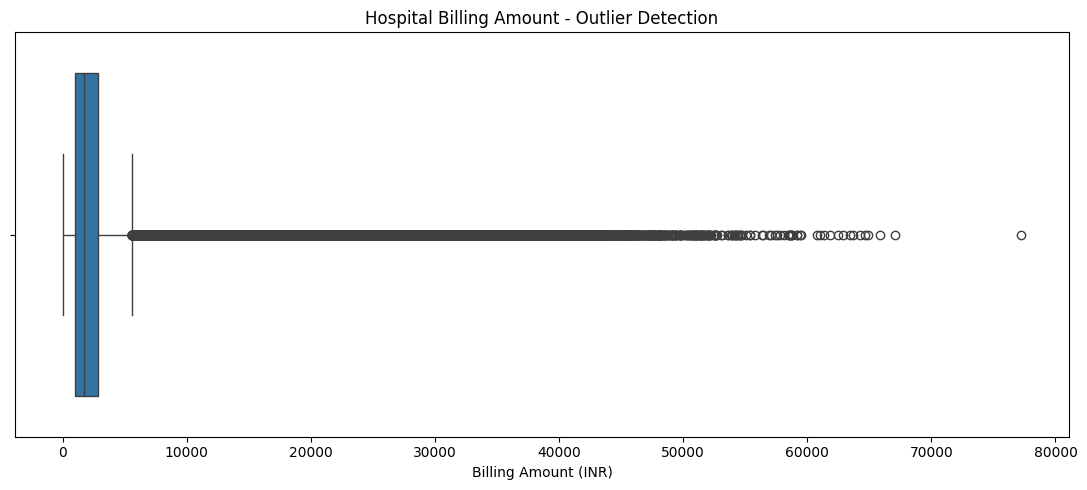

In [18]:

# PHASE 2 - STEP 10
# BILLING OUTLIER DETECTION USING IQR

Q1 = df_clean["billing_amount"].quantile(0.25)
Q3 = df_clean["billing_amount"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = max(0, Q1 - 1.5 * IQR)
upper_limit = Q3 + 1.5 * IQR

# Identify outliers without deleting them
df_clean["billing_outlier"] = (
    (df_clean["billing_amount"] < lower_limit) |
    (df_clean["billing_amount"] > upper_limit)
)

outlier_count = df_clean["billing_outlier"].sum()

print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))

print("Lower limit:", round(lower_limit, 2))
print("Upper limit:", round(upper_limit, 2))

print("Billing outliers identified:", outlier_count)

print(
    "Outlier percentage:",
    round(outlier_count / len(df_clean) * 100, 2),
    "%"
)

# Visualize billing outliers
plt.figure(figsize=(11, 5))

sns.boxplot(
    data=df_clean,
    x="billing_amount"
)

plt.title("Hospital Billing Amount - Outlier Detection")
plt.xlabel("Billing Amount (INR)")
plt.tight_layout()
plt.show()


In [19]:

# PHASE 2 - STEP 11
# CATEGORICAL DATA VALIDATION

expected_hospitals = [
    "Pune Central Hospital",
    "Shivaji Nagar Hospital",
    "Hadapsar Community Hospital",
    "Kothrud Community Hospital"
]

expected_departments = [
    "General Medicine",
    "Cardiology",
    "Orthopedics",
    "Pediatrics",
    "Neurology",
    "Emergency",
    "Gynecology"
]

expected_visit_types = [
    "OPD",
    "Admission"
]

# Standardize text columns
for col in ["hospital", "department", "visit_type", "diagnosis_code"]:
    df_clean[col] = df_clean[col].astype("string").str.strip()

# Check unexpected values
print("Unexpected hospital names:")
print(set(df_clean["hospital"].dropna().unique()) - set(expected_hospitals))

print("\nUnexpected departments:")
print(set(df_clean["department"].dropna().unique()) - set(expected_departments))

print("\nUnexpected visit types:")
print(set(df_clean["visit_type"].dropna().unique()) - set(expected_visit_types))

# Validate patient ages
print("\nInvalid ages:", (
    ~df_clean["patient_age"].between(0, 120)
).sum())

# Validate billing
print("Negative billing values:", (
    df_clean["billing_amount"] < 0
).sum())

# Validate laboratory test counts
print("Negative laboratory values:", (
    df_clean["lab_tests"] < 0
).sum())


Unexpected hospital names:
set()

Unexpected departments:
set()

Unexpected visit types:
set()

Invalid ages: 0
Negative billing values: 0
Negative laboratory values: 0


In [20]:

# PHASE 2 - STEP 12
# FINAL DATA QUALITY REPORT

final_quality_report = pd.DataFrame({
    "Column": df_clean.columns,
    "Data Type": df_clean.dtypes.astype(str).values,
    "Missing Values": df_clean.isnull().sum().values,
    "Missing Percentage": (
        df_clean.isnull().mean().values * 100
    ).round(2)
})

print("=" * 65)
print("FINAL HOSPITAL DATA QUALITY REPORT")
print("=" * 65)

display(final_quality_report)
print("\nFINAL DATASET SUMMARY")
print("Total records:", len(df_clean))
print("Total columns:", len(df_clean.columns))
print("Total missing cells:", df_clean.isnull().sum().sum())
print("Exact duplicates:", df_clean.duplicated().sum())
print("Duplicate record IDs:", df_clean["record_id"].duplicated().sum())

print("\nHOSPITAL DISTRIBUTION")
display(df_clean["hospital"].value_counts())

print("\nVISIT TYPE DISTRIBUTION")
display(df_clean["visit_type"].value_counts())
print("\nPATIENT AGE SUMMARY")
display(df_clean["patient_age"].describe())

print("\nBILLING SUMMARY")
display(df_clean["billing_amount"].describe())


FINAL HOSPITAL DATA QUALITY REPORT


,Column,Data Type,Missing Values,Missing Percentage
0,record_id,int64,0,0.0
1,patient_id,object,0,0.0
2,hospital,string,0,0.0
3,visit_date,datetime64[ns],0,0.0
4,department,string,0,0.0
5,visit_type,string,0,0.0
6,patient_age,int64,0,0.0
7,lab_tests,int64,0,0.0
8,billing_amount,float64,0,0.0
9,diagnosis_code,string,0,0.0



FINAL DATASET SUMMARY
Total records: 499500
Total columns: 13
Total missing cells: 0
Exact duplicates: 0
Duplicate record IDs: 0

HOSPITAL DISTRIBUTION


hospital
Pune Central Hospital          159447
Shivaji Nagar Hospital         134989
Hadapsar Community Hospital    114768
Kothrud Community Hospital      90296
Name: count, dtype: Int64


VISIT TYPE DISTRIBUTION


visit_type
OPD          439338
Admission     60162
Name: count, dtype: Int64


PATIENT AGE SUMMARY


count    499500.000000
mean         45.535331
std          25.701704
min           1.000000
25%          24.000000
50%          46.000000
75%          68.000000
max          90.000000
Name: patient_age, dtype: float64


BILLING SUMMARY


count    499500.000000
mean       3650.377208
std        5902.885858
min           6.570000
25%        1017.410000
50%        1703.180000
75%        2857.420000
max       77232.780000
Name: billing_amount, dtype: float64

In [21]:

# PHASE 2 - STEP 13
# BEFORE AND AFTER CLEANING COMPARISON

comparison = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Missing Values",
        "Exact Duplicate Records",
        "Missing Patient Ages",
        "Missing Laboratory Values",
        "Missing Billing Values",
        "Missing Visit Dates"
    ],
    "Before Cleaning": [
        len(df_raw),
        df_raw.isnull().sum().sum(),
        df_raw.duplicated().sum(),
        df_raw["patient_age"].isna().sum(),
        df_raw["lab_tests"].isna().sum(),
        df_raw["billing_amount"].isna().sum(),
        df_raw["visit_date"].isna().sum()
    ],
    "After Cleaning": [
        len(df_clean),
        df_clean.isnull().sum().sum(),
        df_clean.duplicated().sum(),
        df_clean["patient_age"].isna().sum(),
        df_clean["lab_tests"].isna().sum(),
        df_clean["billing_amount"].isna().sum(),
        df_clean["visit_date"].isna().sum()
    ]
})

display(comparison)


,Metric,Before Cleaning,After Cleaning
0,Total Records,500000,499500
1,Missing Values,20317,0
2,Exact Duplicate Records,0,0
3,Missing Patient Ages,10000,0
4,Missing Laboratory Values,3000,0
5,Missing Billing Values,2000,0
6,Missing Visit Dates,500,0


In [22]:

# PHASE 2 - STEP 14
# EXPORT CLEANED DATASET

cleaned_file = "data/processed/hospital_demand_cleaned.csv"

df_clean.to_csv(
    cleaned_file,
    index=False
)

print("Cleaned dataset exported successfully!")
print("File:", cleaned_file)
print("Records:", len(df_clean))
print("Columns:", len(df_clean.columns))

print(
    "File size (MB):",
    round(os.path.getsize(cleaned_file) / (1024 * 1024), 2)
)

# Verify exported file
df_verification = pd.read_csv(cleaned_file)

print("\nExport verification:")
print("File exists:", os.path.exists(cleaned_file))
print("Reloaded shape:", df_verification.shape)


Cleaned dataset exported successfully!
File: data/processed/hospital_demand_cleaned.csv
Records: 499500
Columns: 13
File size (MB): 51.06

Export verification:
File exists: True
Reloaded shape: (499500, 13)


# PHASE 3 – EXPLORATORY DATA ANALYSIS

In [23]:
# Load cleaned dataset
df = pd.read_csv(
    "data/processed/hospital_demand_cleaned.csv",
    parse_dates=["visit_date", "discharge_date"]
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Dataset loaded successfully!
Dataset shape: (499500, 13)

Columns:
['record_id', 'patient_id', 'hospital', 'visit_date', 'department', 'visit_type', 'patient_age', 'lab_tests', 'billing_amount', 'diagnosis_code', 'length_of_stay', 'discharge_date', 'billing_outlier']


,record_id,patient_id,hospital,visit_date,department,visit_type,patient_age,lab_tests,billing_amount,diagnosis_code,length_of_stay,discharge_date,billing_outlier
0,1,PAT0134487,Shivaji Nagar Hospital,2026-01-10,Neurology,OPD,30,2,1855.45,D005,0,2026-01-10,False
1,2,PAT0030038,Pune Central Hospital,2024-09-25,Orthopedics,OPD,75,4,838.68,D005,0,2024-09-25,False
2,3,PAT0144663,Kothrud Community Hospital,2026-04-22,General Medicine,OPD,45,1,2144.82,D004,0,2026-04-22,False
3,4,PAT0076778,Shivaji Nagar Hospital,2025-09-18,Cardiology,OPD,88,2,2151.45,D001,0,2025-09-18,False
4,5,PAT0020454,Hadapsar Community Hospital,2023-05-09,Pediatrics,Admission,20,8,16143.25,D001,7,2023-05-16,True


In [24]:
print("Date range:")
print("Start:", df["visit_date"].min())
print("End:", df["visit_date"].max())

print("\nHospital count:")
print(df["hospital"].nunique())

print("\nVisit types:")
display(df["visit_type"].value_counts())

print("\nDepartment distribution:")
display(df["department"].value_counts())

print("\nMissing values:")
display(df.isnull().sum())

Date range:
Start: 2023-01-01 00:00:00
End: 2026-10-31 00:00:00

Hospital count:
4

Visit types:


visit_type
OPD          439338
Admission     60162
Name: count, dtype: int64


Department distribution:


department
General Medicine    139665
Emergency            74865
Pediatrics           70490
Orthopedics          65066
Cardiology           60031
Neurology            49630
Gynecology           39753
Name: count, dtype: int64


Missing values:


record_id          0
patient_id         0
hospital           0
visit_date         0
department         0
visit_type         0
patient_age        0
lab_tests          0
billing_amount     0
diagnosis_code     0
length_of_stay     0
discharge_date     0
billing_outlier    0
dtype: int64

In [25]:
hospital_summary = (
    df.groupby("hospital")
    .agg(
        total_visits=("record_id", "count"),
        opd_visits=("visit_type", lambda x: (x == "OPD").sum()),
        admissions=("visit_type", lambda x: (x == "Admission").sum()),
        average_billing=("billing_amount", "mean")
    )
    .reset_index()
)

display(hospital_summary)

,hospital,total_visits,opd_visits,admissions,average_billing
0,Hadapsar Community Hospital,114768,101025,13743,3639.837233
1,Kothrud Community Hospital,90296,79336,10960,3686.654019
2,Pune Central Hospital,159447,140305,19142,3632.125818
3,Shivaji Nagar Hospital,134989,118672,16317,3656.630536


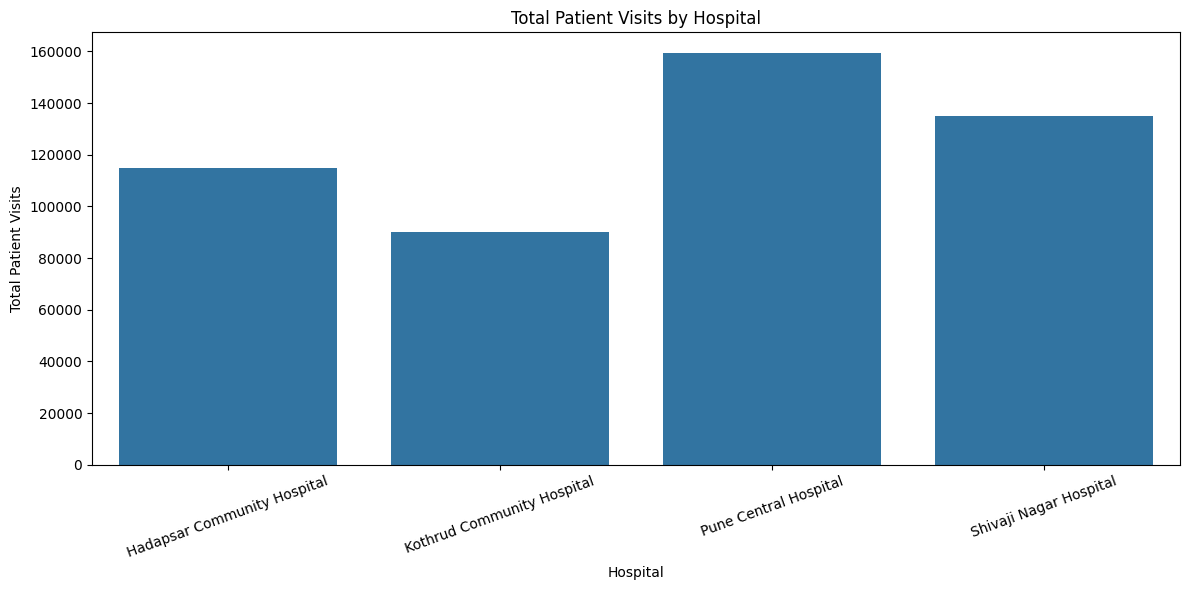

In [26]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=hospital_summary,
    x="hospital",
    y="total_visits"
)

plt.title("Total Patient Visits by Hospital")
plt.xlabel("Hospital")
plt.ylabel("Total Patient Visits")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

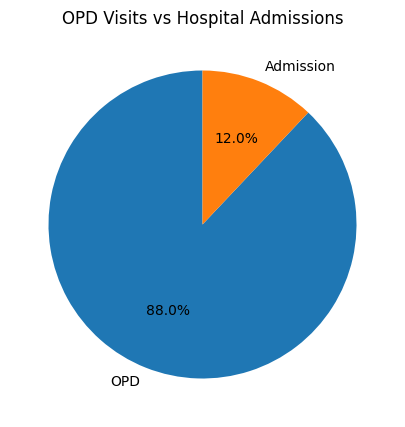

In [27]:
visit_summary = (
    df["visit_type"]
    .value_counts()
    .reset_index()
)

visit_summary.columns = ["visit_type", "count"]

plt.figure(figsize=(8, 5))

plt.pie(
    visit_summary["count"],
    labels=visit_summary["visit_type"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("OPD Visits vs Hospital Admissions")
plt.show()

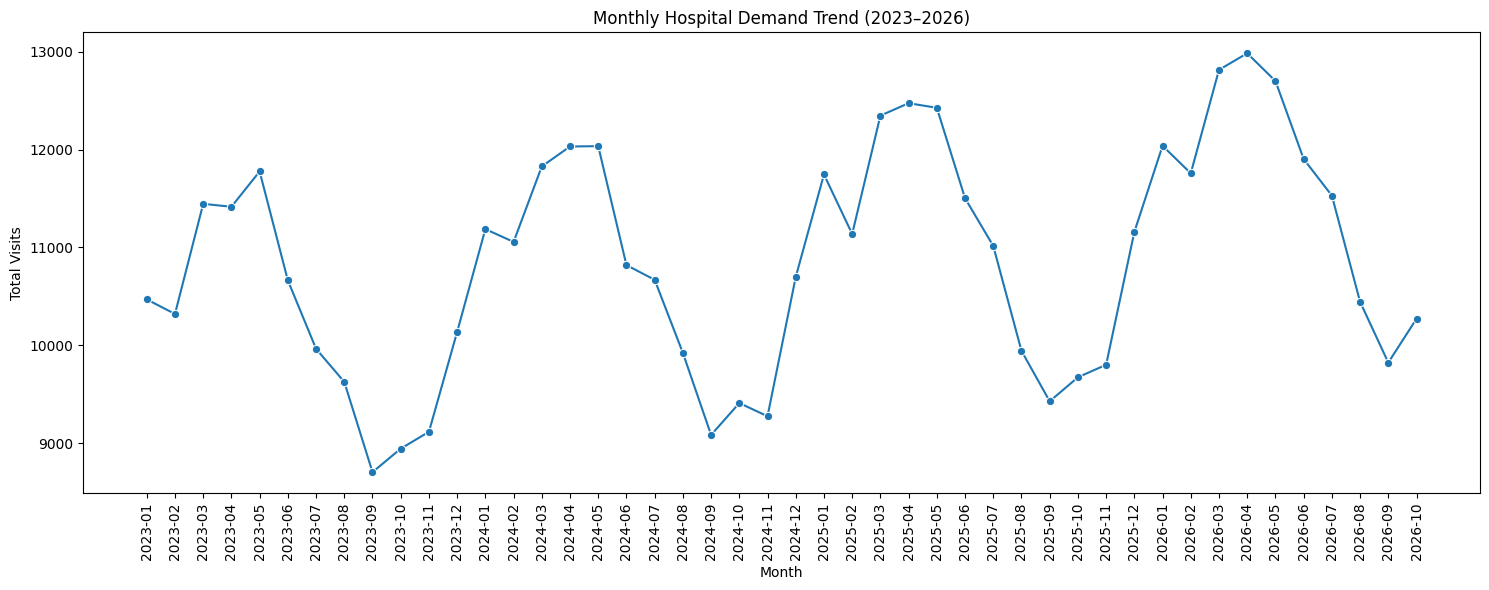

In [28]:
df["month"] = df["visit_date"].dt.to_period("M").astype(str)

monthly_demand = (
    df.groupby("month")
    .size()
    .reset_index(name="total_visits")
)

plt.figure(figsize=(15, 6))

sns.lineplot(
    data=monthly_demand,
    x="month",
    y="total_visits",
    marker="o"
)

plt.title("Monthly Hospital Demand Trend (2023–2026)")
plt.xlabel("Month")
plt.ylabel("Total Visits")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [29]:
os.makedirs("data/processed", exist_ok=True)
os.makedirs("visualizations", exist_ok=True)

hospital_summary.to_csv(
    "data/processed/hospital_summary.csv",
    index=False
)

monthly_demand.to_csv(
    "data/processed/monthly_demand.csv",
    index=False
)

print("EDA initial analysis completed!")
print("Hospital summary and monthly demand files saved.")

EDA initial analysis completed!
Hospital summary and monthly demand files saved.


# WEEKLY DEMAND AGGREGATION

In [30]:
# Convert visit dates into weekly periods (Monday to Sunday)
df["visit_date"] = pd.to_datetime(df["visit_date"])

first_date = df["visit_date"].min().normalize()
last_date = df["visit_date"].max().normalize()

# Identify complete weeks only
first_monday = first_date + pd.Timedelta(
    days=(7 - first_date.weekday()) % 7
)

last_sunday = last_date - pd.Timedelta(
    days=(last_date.weekday() + 1) % 7
)

last_monday = last_sunday - pd.Timedelta(days=6)

# Exclude incomplete weeks at the beginning and end
df_weekly_source = df[
    (df["visit_date"] >= first_monday) &
    (df["visit_date"] <= last_sunday)
].copy()

# Create weekly start date
df_weekly_source["week_start"] = (
    df_weekly_source["visit_date"]
    .dt.to_period("W-SUN")
    .dt.start_time
)

# Create indicators
df_weekly_source["admission_flag"] = (
    df_weekly_source["visit_type"] == "Admission"
).astype(int)

df_weekly_source["opd_flag"] = (
    df_weekly_source["visit_type"] == "OPD"
).astype(int)

# Aggregate weekly demand by hospital
weekly_demand = (
    df_weekly_source
    .groupby(["hospital", "week_start"])
    .agg(
        total_visits=("record_id", "count"),
        admissions=("admission_flag", "sum"),
        opd_visits=("opd_flag", "sum")
    )
    .reset_index()
)

# Create a complete hospital-week grid
all_weeks = pd.date_range(
    start=first_monday,
    end=last_monday,
    freq="W-MON"
)

all_hospitals = sorted(df["hospital"].unique())

full_index = pd.MultiIndex.from_product(
    [all_hospitals, all_weeks],
    names=["hospital", "week_start"]
)

weekly_demand = (
    weekly_demand
    .set_index(["hospital", "week_start"])
    .reindex(full_index, fill_value=0)
    .reset_index()
)

weekly_demand = weekly_demand.sort_values(
    ["hospital", "week_start"]
).reset_index(drop=True)

print("Weekly demand dataset created!")
print("Number of hospitals:", weekly_demand["hospital"].nunique())
print("Number of weeks:", weekly_demand["week_start"].nunique())
print("Total rows:", len(weekly_demand))

display(weekly_demand.head(12))

Weekly demand dataset created!
Number of hospitals: 4
Number of weeks: 199
Total rows: 796


,hospital,week_start,total_visits,admissions,opd_visits
0,Hadapsar Community Hospital,2023-01-02,530,52,478
1,Hadapsar Community Hospital,2023-01-09,567,85,482
2,Hadapsar Community Hospital,2023-01-16,545,71,474
3,Hadapsar Community Hospital,2023-01-23,575,76,499
4,Hadapsar Community Hospital,2023-01-30,572,75,497
5,Hadapsar Community Hospital,2023-02-06,609,83,526
6,Hadapsar Community Hospital,2023-02-13,574,69,505
7,Hadapsar Community Hospital,2023-02-20,598,74,524
8,Hadapsar Community Hospital,2023-02-27,638,70,568
9,Hadapsar Community Hospital,2023-03-06,525,67,458


/root/venv/lib/python3.13/site-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/root/venv/lib/python3.13/site-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/root/venv/lib/python3.13/site-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/root/venv/lib/python3.13/site-packages/seaborn/_base.py:949: FutureWarning: When 

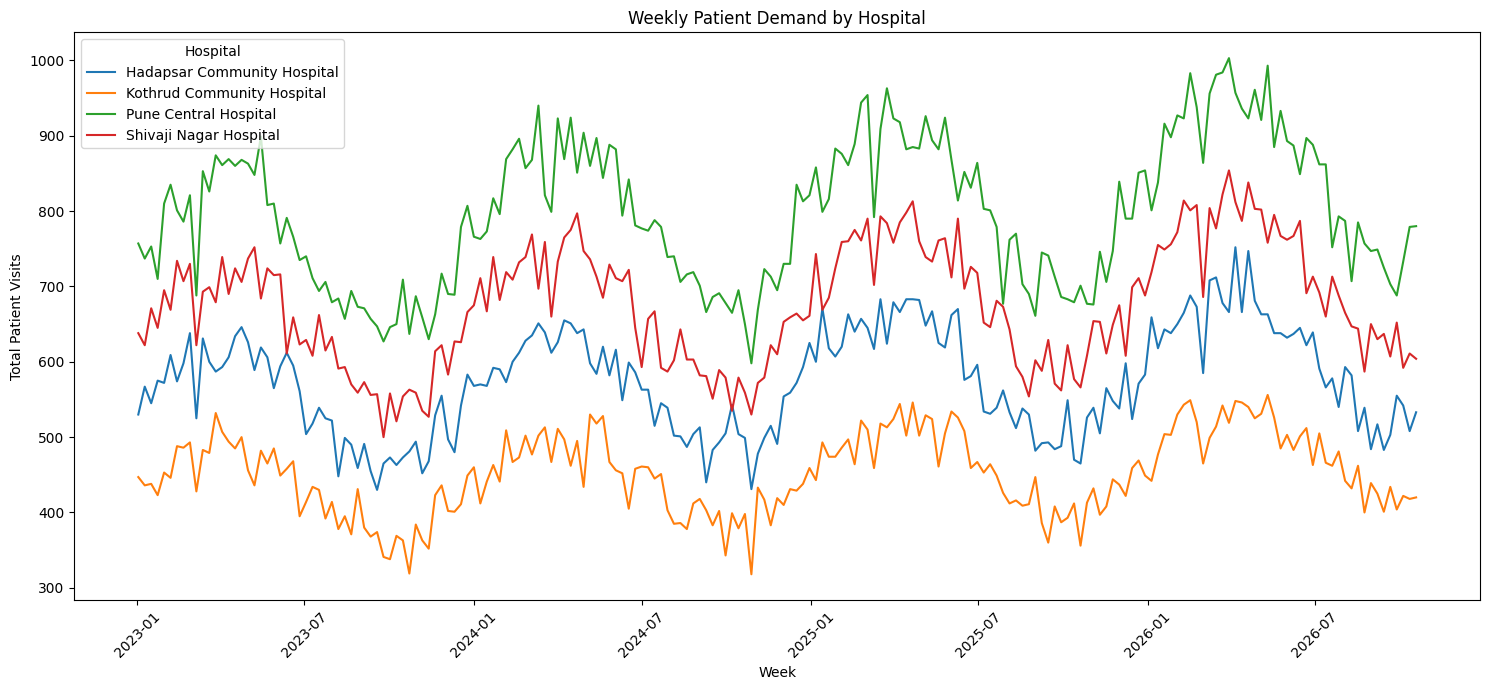

In [31]:
plt.figure(figsize=(15, 7))

sns.lineplot(
    data=weekly_demand,
    x="week_start",
    y="total_visits",
    hue="hospital"
)

plt.title("Weekly Patient Demand by Hospital")
plt.xlabel("Week")
plt.ylabel("Total Patient Visits")
plt.xticks(rotation=45)
plt.legend(title="Hospital")
plt.tight_layout()
plt.show()

In [32]:
weekly_file = "data/processed/weekly_hospital_demand.csv"

weekly_demand.to_csv(weekly_file, index=False)

print("Weekly dataset saved successfully!")
print("File:", weekly_file)
print("Rows:", len(weekly_demand))
print("Columns:", weekly_demand.columns.tolist())

Weekly dataset saved successfully!
File: data/processed/weekly_hospital_demand.csv
Rows: 796
Columns: ['hospital', 'week_start', 'total_visits', 'admissions', 'opd_visits']


# PHASE 5 – TIME SERIES ANALYSIS

In [33]:
# Load weekly demand dataset
weekly_demand = pd.read_csv(
    "data/processed/weekly_hospital_demand.csv",
    parse_dates=["week_start"]
)

weekly_demand = weekly_demand.sort_values(
    ["hospital", "week_start"]
).reset_index(drop=True)

print("Weekly dataset loaded successfully!")
print("Shape:", weekly_demand.shape)
print("Hospitals:", weekly_demand["hospital"].nunique())
print("Weeks:", weekly_demand["week_start"].nunique())

# Check data quality
print("\nMissing values:")
display(weekly_demand.isnull().sum())

print("\nDuplicate hospital-week records:",
      weekly_demand.duplicated(
          subset=["hospital", "week_start"]
      ).sum())

print("\nDate range:",
      weekly_demand["week_start"].min(),
      "to",
      weekly_demand["week_start"].max())

Weekly dataset loaded successfully!
Shape: (796, 5)
Hospitals: 4
Weeks: 199

Missing values:


hospital        0
week_start      0
total_visits    0
admissions      0
opd_visits      0
dtype: int64


Duplicate hospital-week records: 0

Date range: 2023-01-02 00:00:00 to 2026-10-19 00:00:00


,week_start,total_visits,total_admissions,total_opd
0,2023-01-02,2372,279,2093
1,2023-01-09,2362,324,2038
2,2023-01-16,2407,285,2122
3,2023-01-23,2353,282,2071
4,2023-01-30,2530,314,2216


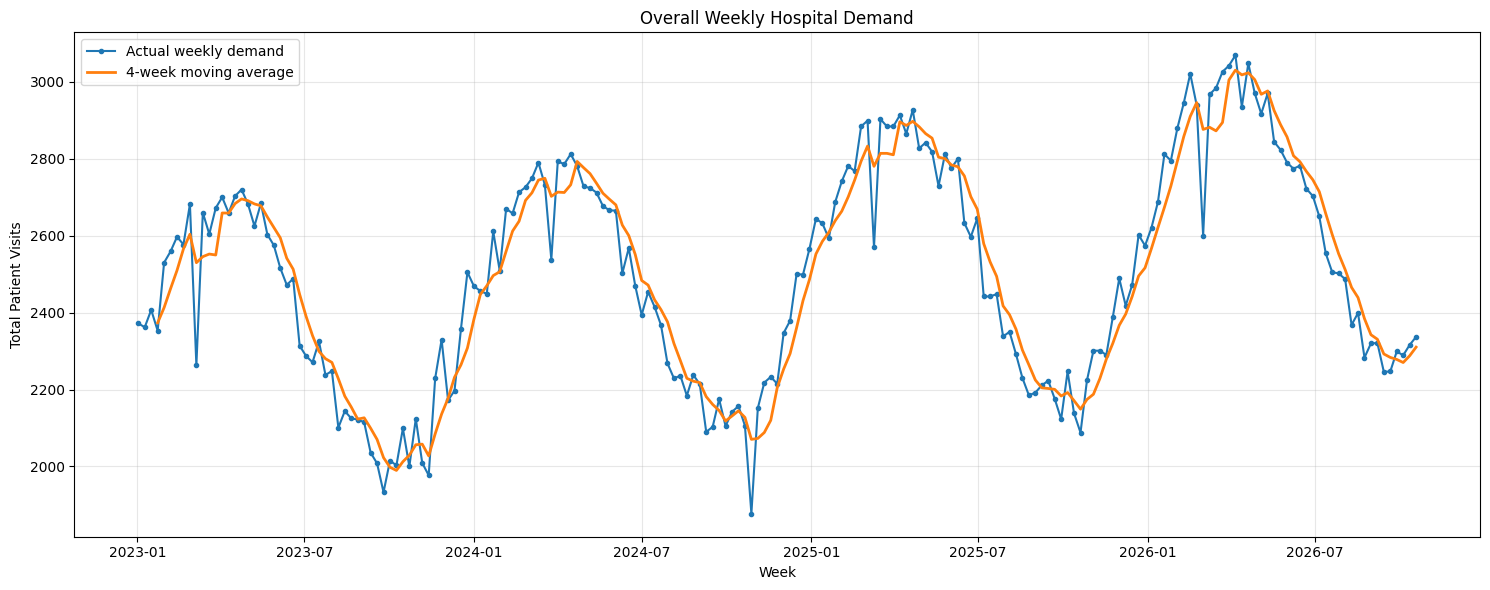

In [34]:
weekly_total = (
    weekly_demand
    .groupby("week_start")
    .agg(
        total_visits=("total_visits", "sum"),
        total_admissions=("admissions", "sum"),
        total_opd=("opd_visits", "sum")
    )
    .reset_index()
)

display(weekly_total.head())

plt.figure(figsize=(15, 6))

plt.plot(
    weekly_total["week_start"],
    weekly_total["total_visits"],
    marker="o",
    markersize=3,
    label="Actual weekly demand"
)

plt.plot(
    weekly_total["week_start"],
    weekly_total["total_visits"].rolling(4).mean(),
    linewidth=2,
    label="4-week moving average"
)

plt.title("Overall Weekly Hospital Demand")
plt.xlabel("Week")
plt.ylabel("Total Patient Visits")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

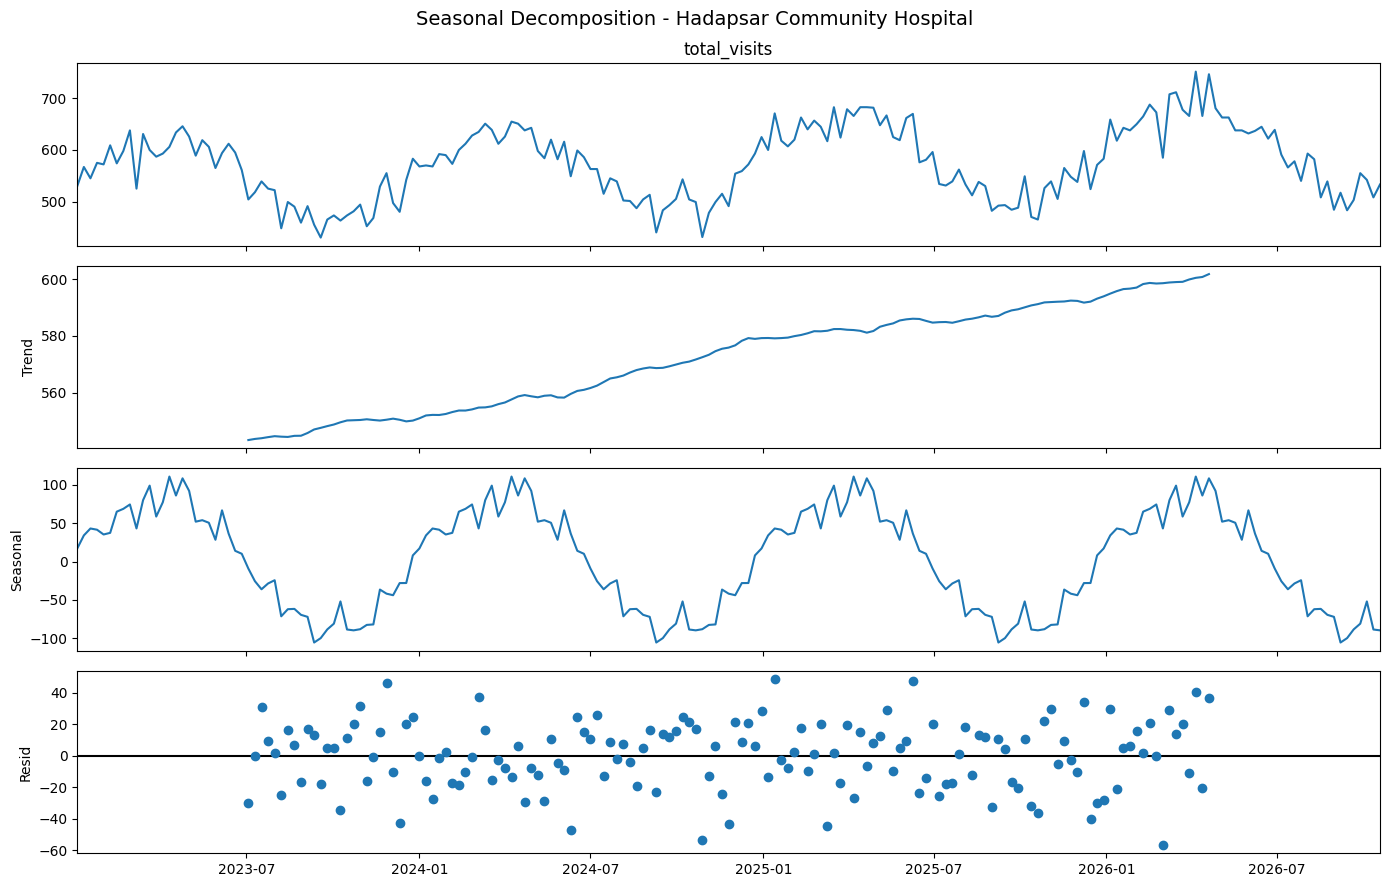

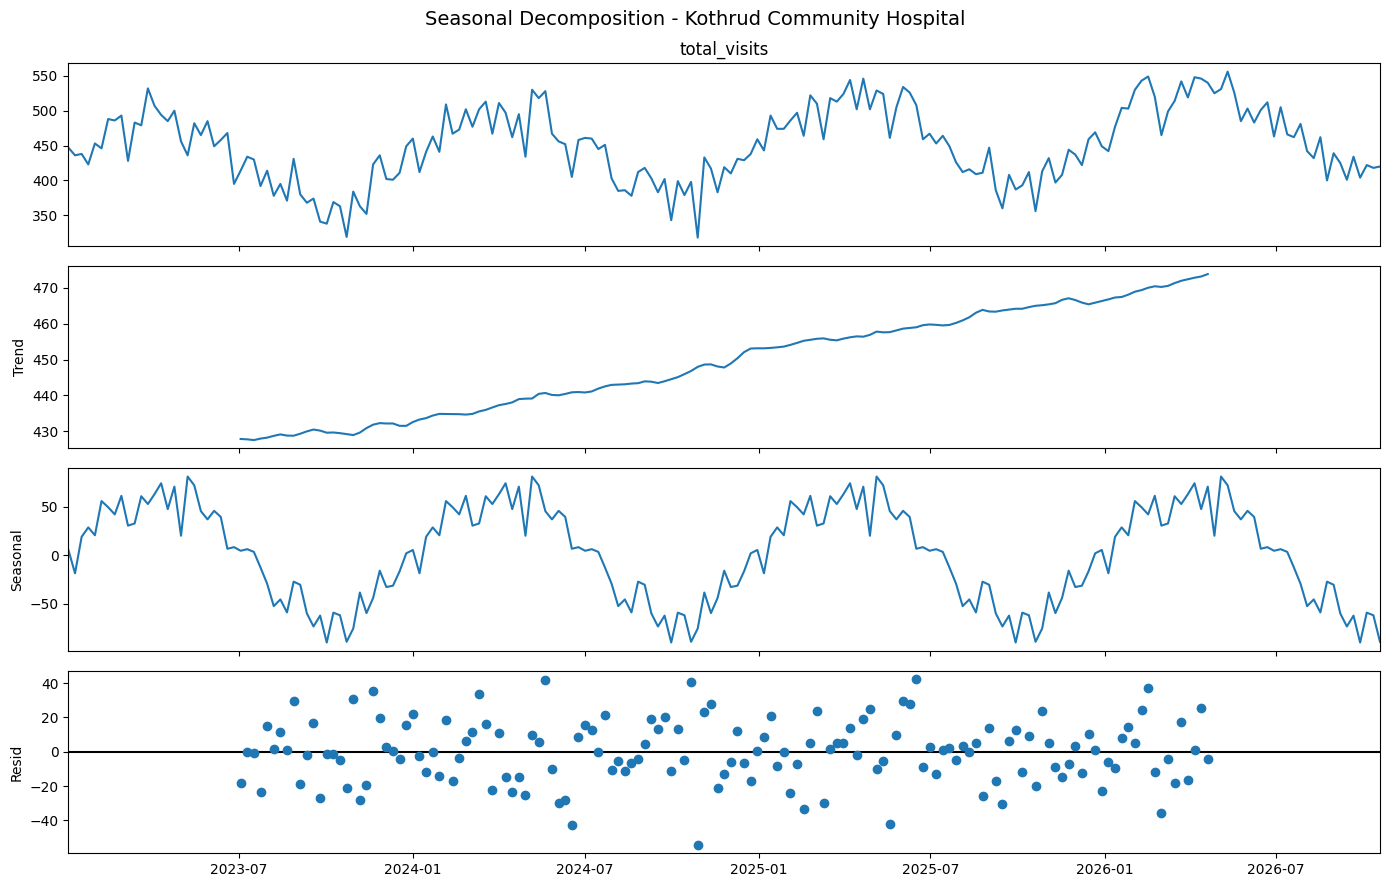

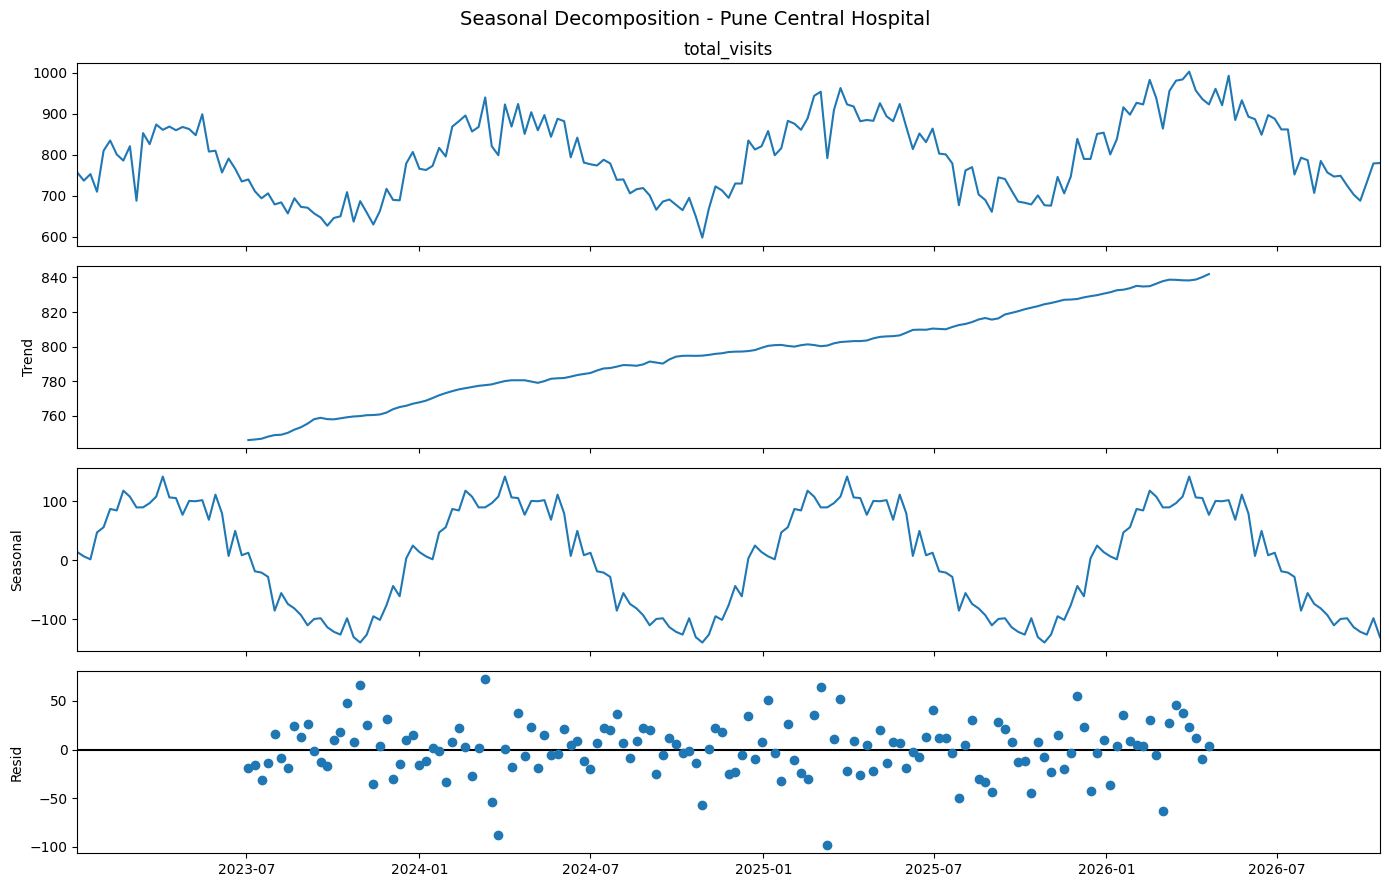

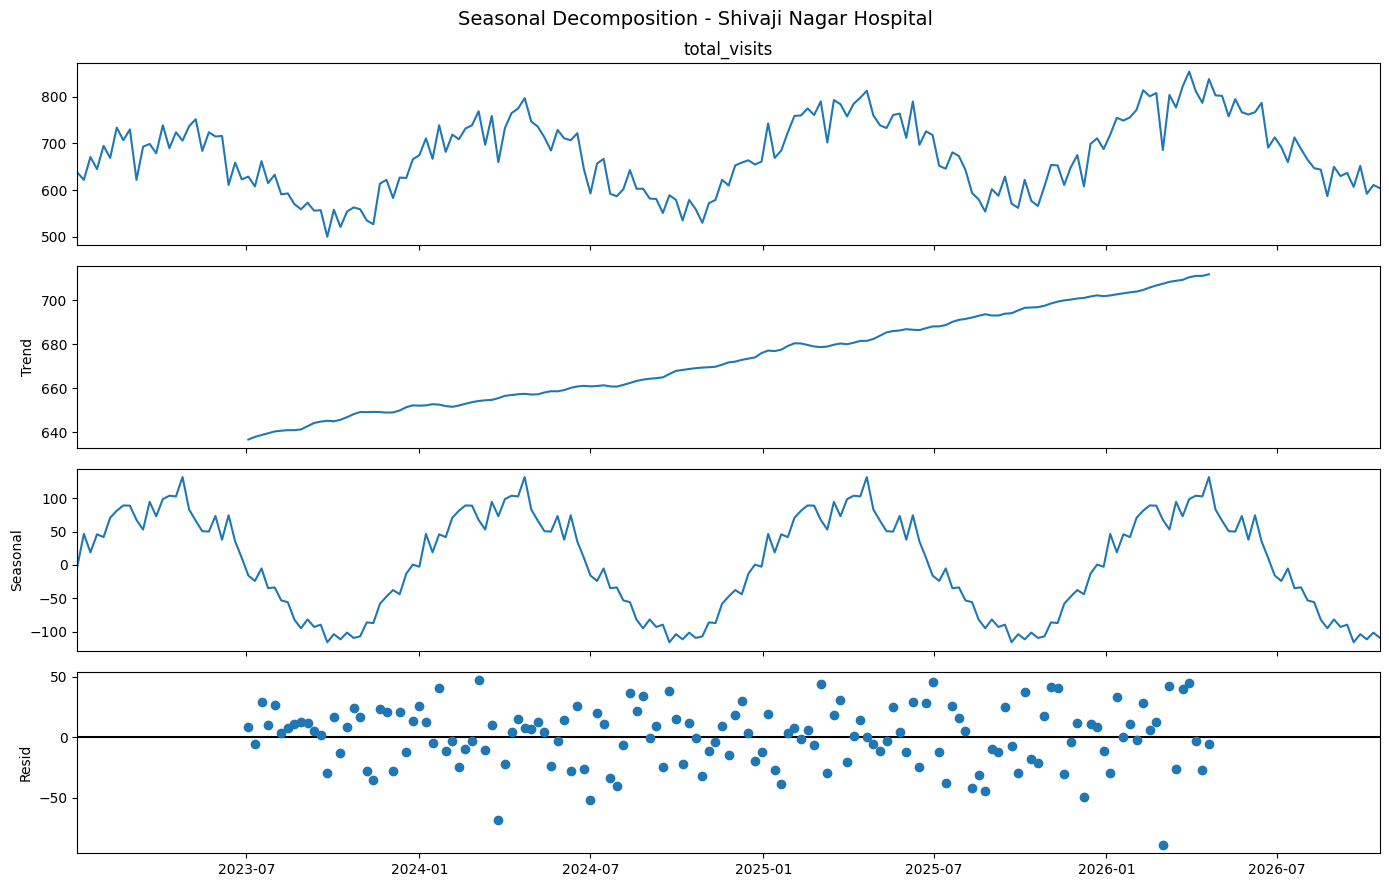

In [35]:
from statsmodels.tsa.seasonal import seasonal_decompose

for hospital in weekly_demand["hospital"].unique():

    hospital_data = (
        weekly_demand[
            weekly_demand["hospital"] == hospital
        ]
        .sort_values("week_start")
        .set_index("week_start")
    )

    demand_series = hospital_data["total_visits"]

    decomposition = seasonal_decompose(
        demand_series,
        model="additive",
        period=52
    )

    fig = decomposition.plot()
    fig.set_size_inches(14, 9)
    fig.suptitle(
        f"Seasonal Decomposition - {hospital}",
        fontsize=14
    )
    plt.tight_layout()
    plt.show()

In [36]:
from statsmodels.tsa.stattools import adfuller

for hospital in weekly_demand["hospital"].unique():

    series = (
        weekly_demand[
            weekly_demand["hospital"] == hospital
        ]
        .sort_values("week_start")["total_visits"]
    )

    result = adfuller(series)

    print("\nHospital:", hospital)
    print("ADF Statistic:", round(result[0], 4))
    print("p-value:", round(result[1], 6))

    if result[1] < 0.05:
        print("Result: Evidence of stationarity")
    else:
        print("Result: Evidence of non-stationarity")


Hospital: Hadapsar Community Hospital
ADF Statistic: -5.2358
p-value: 7e-06
Result: Evidence of stationarity

Hospital: Kothrud Community Hospital
ADF Statistic: -5.523
p-value: 2e-06
Result: Evidence of stationarity

Hospital: Pune Central Hospital
ADF Statistic: -5.4385
p-value: 3e-06
Result: Evidence of stationarity

Hospital: Shivaji Nagar Hospital
ADF Statistic: -5.1942
p-value: 9e-06
Result: Evidence of stationarity
/tmp/ipykernel_510/2989177715.py:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series)
/tmp/ipykernel_510/2989177715.py:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. I

In [37]:
# Reserve final 13 weeks for testing

all_weeks = sorted(
    weekly_demand["week_start"].unique()
)

test_weeks = all_weeks[-13:]
train_weeks = all_weeks[:-13]

train_data = weekly_demand[
    weekly_demand["week_start"].isin(train_weeks)
].copy()

test_data = weekly_demand[
    weekly_demand["week_start"].isin(test_weeks)
].copy()

print("Training weeks:", len(train_weeks))
print("Testing weeks:", len(test_weeks))

print("\nTraining records:", len(train_data))
print("Testing records:", len(test_data))

print("\nTraining period:",
      train_data["week_start"].min(),
      "to",
      train_data["week_start"].max())

print("\nTesting period:",
      test_data["week_start"].min(),
      "to",
      test_data["week_start"].max())

print("\nHospitals in training:", train_data["hospital"].nunique())
print("Hospitals in testing:", test_data["hospital"].nunique())

Training weeks: 186
Testing weeks: 13

Training records: 744
Testing records: 52

Training period: 2023-01-02 00:00:00 to 2026-07-20 00:00:00

Testing period: 2026-07-27 00:00:00 to 2026-10-19 00:00:00

Hospitals in training: 4
Hospitals in testing: 4


In [38]:
weekly_total.to_csv(
    "data/processed/overall_weekly_demand.csv",
    index=False
)

train_data.to_csv(
    "data/processed/training_data.csv",
    index=False
)

test_data.to_csv(
    "data/processed/testing_data.csv",
    index=False
)

print("Phase 5 analysis files saved successfully!")

Phase 5 analysis files saved successfully!


# PHASE 6 – BASELINE FORECASTING MODELS

In [39]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

print("Forecasting libraries imported successfully!")

Forecasting libraries imported successfully!


In [40]:
# Baseline forecasting for all four hospitals

baseline_results = []
baseline_predictions = []

for hospital in weekly_demand["hospital"].unique():

    hospital_data = (
        weekly_demand[
            weekly_demand["hospital"] == hospital
        ]
        .sort_values("week_start")
        .reset_index(drop=True)
    )

    # Split into training and testing
    train = hospital_data.iloc[:-13].copy()
    test = hospital_data.iloc[-13:].copy()

    actual = test["total_visits"].values

    # Model 1: Naive forecast
    naive_forecast = np.repeat(
        train["total_visits"].iloc[-1],
        len(test)
    )

    # Model 2: Seasonal naive forecast (52-week lag)
    seasonal_forecast = (
        hospital_data["total_visits"]
        .iloc[len(train) - 52:len(train) - 52 + len(test)]
        .values
    )

    # Evaluate both models
    models = {
        "Naive": naive_forecast,
        "Seasonal Naive": seasonal_forecast
    }

    for model_name, predictions in models.items():

        mae = mean_absolute_error(actual, predictions)

        rmse = np.sqrt(
            mean_squared_error(actual, predictions)
        )

        mape = np.mean(
            np.abs((actual - predictions) / actual)
        ) * 100

        baseline_results.append({
            "hospital": hospital,
            "model": model_name,
            "MAE": mae,
            "RMSE": rmse,
            "MAPE": mape
        })

        for i in range(len(test)):
            baseline_predictions.append({
                "hospital": hospital,
                "week_start": test["week_start"].iloc[i],
                "model": model_name,
                "actual": actual[i],
                "forecast": predictions[i]
            })

baseline_metrics = pd.DataFrame(baseline_results)

baseline_predictions = pd.DataFrame(
    baseline_predictions
)

print("Baseline models completed successfully!")

display(
    baseline_metrics.round(2)
)

Baseline models completed successfully!


,hospital,model,MAE,RMSE,MAPE
0,Hadapsar Community Hospital,Naive,51.15,58.22,10.01
1,Hadapsar Community Hospital,Seasonal Naive,32.85,40.82,6.04
2,Kothrud Community Hospital,Naive,35.69,39.78,8.53
3,Kothrud Community Hospital,Seasonal Naive,30.38,35.43,7.01
4,Pune Central Hospital,Naive,29.31,34.17,3.97
5,Pune Central Hospital,Seasonal Naive,53.85,65.50,7.06
6,Shivaji Nagar Hospital,Naive,81.15,86.13,13.08
7,Shivaji Nagar Hospital,Seasonal Naive,39.46,44.49,6.25


In [41]:
baseline_comparison = (
    baseline_metrics
    .groupby("model")[["MAE", "RMSE", "MAPE"]]
    .mean()
    .reset_index()
)

print("Average baseline model performance:")
display(baseline_comparison.round(2))

Average baseline model performance:


,model,MAE,RMSE,MAPE
0,Naive,49.33,54.57,8.90
1,Seasonal Naive,39.13,46.56,6.59


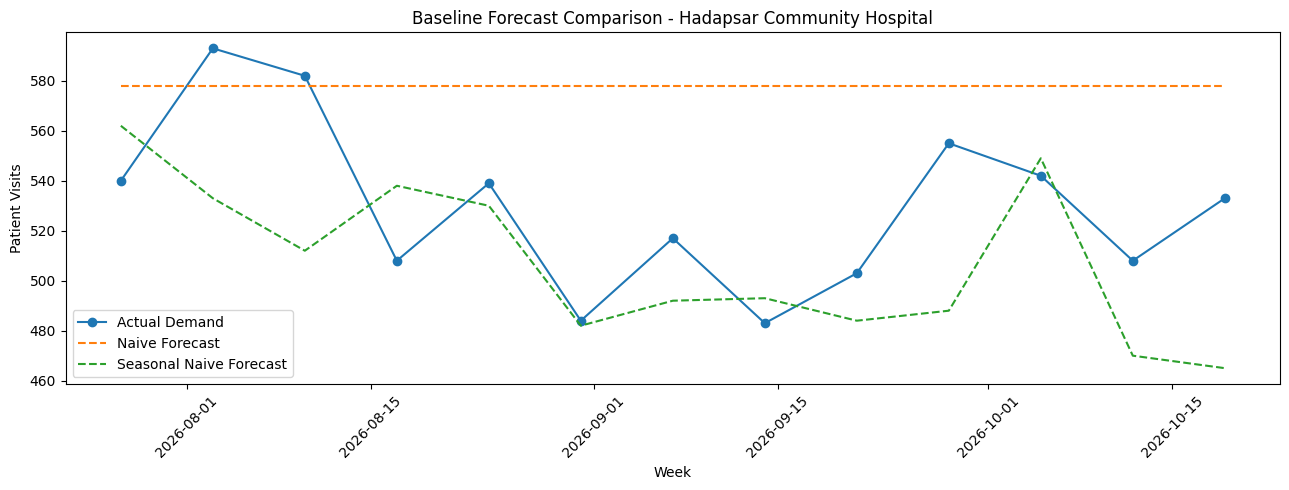

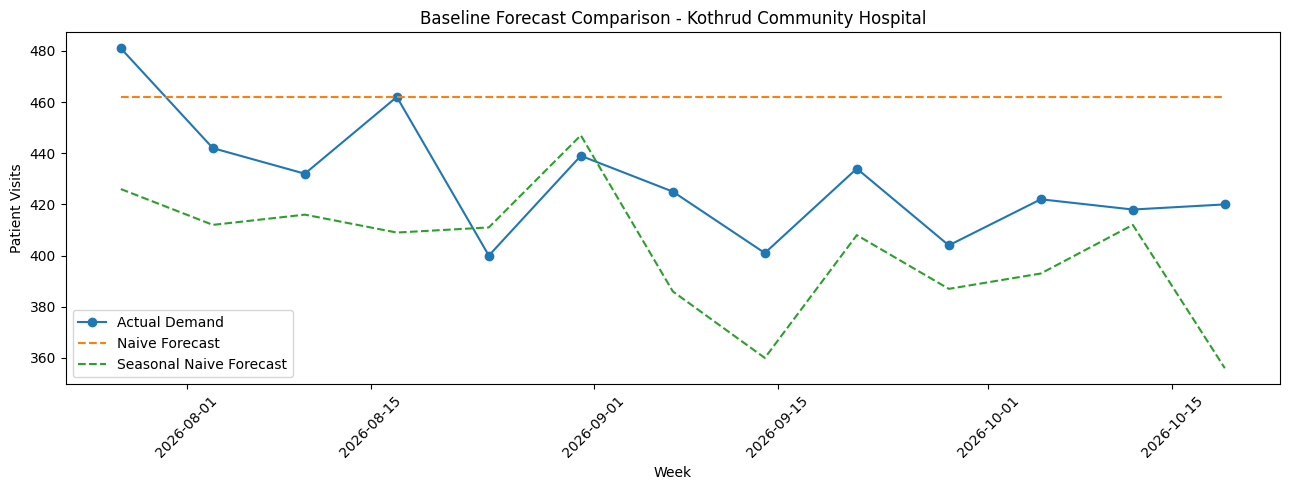

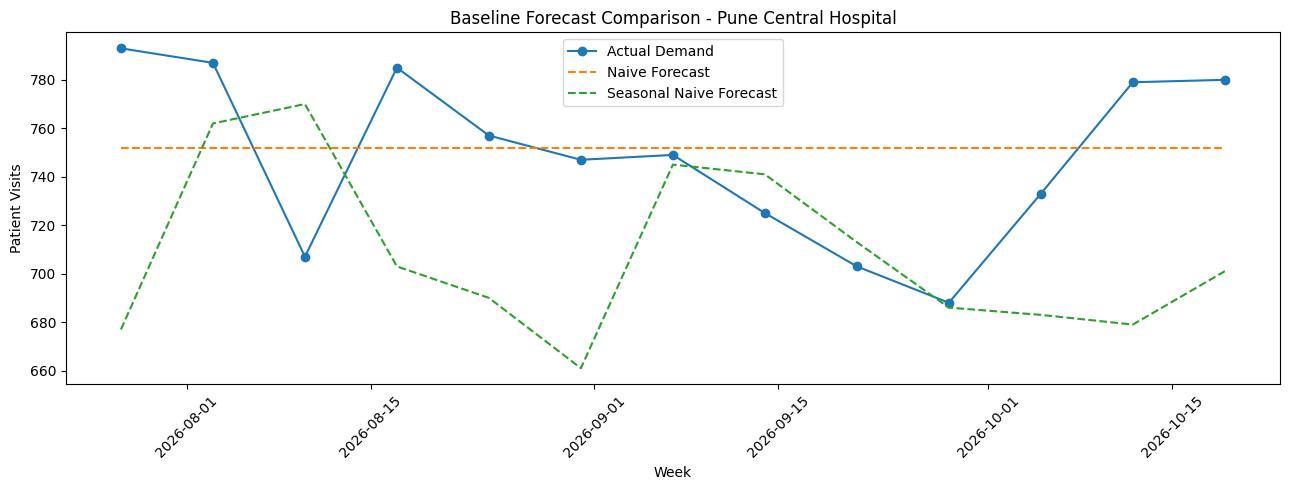

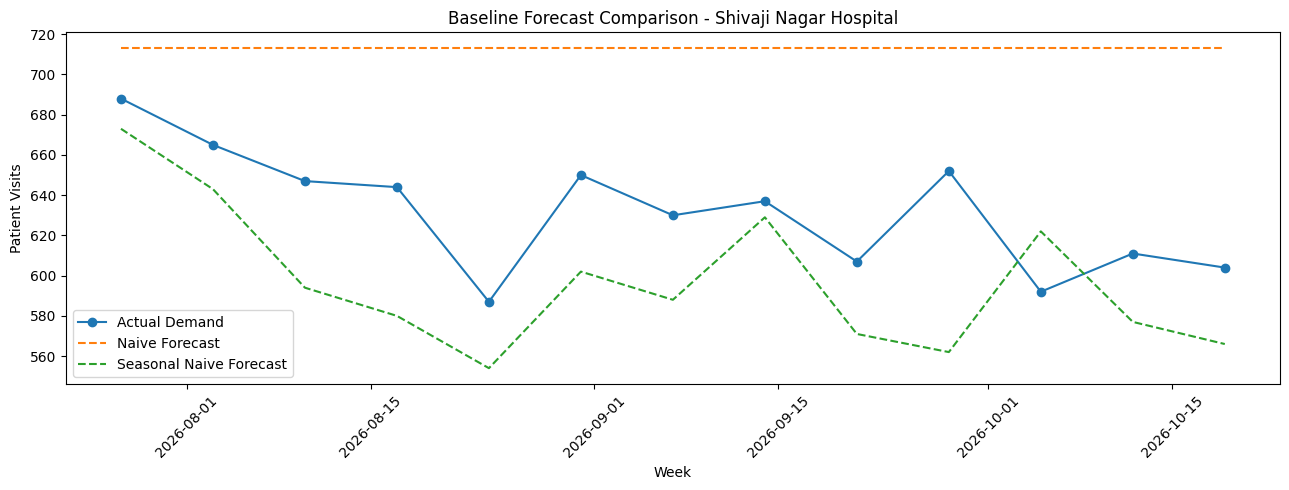

In [42]:
for hospital in weekly_demand["hospital"].unique():

    plot_data = baseline_predictions[
        baseline_predictions["hospital"] == hospital
    ]

    actual_data = (
        plot_data[plot_data["model"] == "Naive"]
        .sort_values("week_start")
    )

    naive_data = (
        plot_data[plot_data["model"] == "Naive"]
        .sort_values("week_start")
    )

    seasonal_data = (
        plot_data[plot_data["model"] == "Seasonal Naive"]
        .sort_values("week_start")
    )

    plt.figure(figsize=(13, 5))

    plt.plot(
        actual_data["week_start"],
        actual_data["actual"],
        marker="o",
        label="Actual Demand"
    )

    plt.plot(
        naive_data["week_start"],
        naive_data["forecast"],
        linestyle="--",
        label="Naive Forecast"
    )

    plt.plot(
        seasonal_data["week_start"],
        seasonal_data["forecast"],
        linestyle="--",
        label="Seasonal Naive Forecast"
    )

    plt.title(f"Baseline Forecast Comparison - {hospital}")
    plt.xlabel("Week")
    plt.ylabel("Patient Visits")
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [43]:
baseline_metrics.to_csv(
    "data/processed/baseline_model_metrics.csv",
    index=False
)

baseline_predictions.to_csv(
    "data/processed/baseline_predictions.csv",
    index=False
)

print("Baseline forecasting results saved successfully!")

Baseline forecasting results saved successfully!


# PHASE 7 – ADVANCED FORECASTING MODELS

In [44]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd
import warnings

warnings.filterwarnings("ignore")

print("ARIMA and SARIMA libraries imported successfully!")

ARIMA and SARIMA libraries imported successfully!


In [45]:
advanced_metrics = []
advanced_predictions = []

for hospital in sorted(weekly_demand["hospital"].unique()):

    hospital_data = (
        weekly_demand[
            weekly_demand["hospital"] == hospital
        ]
        .sort_values("week_start")
        .reset_index(drop=True)
    )

    train = hospital_data.iloc[:-13].copy()
    test = hospital_data.iloc[-13:].copy()

    train_series = train["total_visits"].astype(float)
    actual = test["total_visits"].values

    models = {
        "ARIMA": ARIMA(
            train_series,
            order=(1, 1, 1)
        ),
        "SARIMA": SARIMAX(
            train_series,
            order=(1, 0, 1),
            seasonal_order=(1, 0, 1, 52),
            enforce_stationarity=False,
            enforce_invertibility=False
        )
    }

    for model_name, model in models.items():

        try:
            fitted_model = model.fit()

            forecast_result = fitted_model.get_forecast(
                steps=13
            )

            predictions = np.maximum(
                forecast_result.predicted_mean.values,
                0
            )

            mae = mean_absolute_error(
                actual, predictions
            )

            rmse = np.sqrt(
                mean_squared_error(actual, predictions)
            )

            mape = np.mean(
                np.abs((actual - predictions) / actual)
            ) * 100

            advanced_metrics.append({
                "hospital": hospital,
                "model": model_name,
                "MAE": mae,
                "RMSE": rmse,
                "MAPE": mape,
                "status": "Success"
            })

            for i in range(len(test)):
                advanced_predictions.append({
                    "hospital": hospital,
                    "week_start": test["week_start"].iloc[i],
                    "model": model_name,
                    "actual": actual[i],
                    "forecast": predictions[i]
                })

            print(hospital, "-", model_name, "completed")

        except Exception as e:

            print(hospital, "-", model_name, "failed:", str(e))

            advanced_metrics.append({
                "hospital": hospital,
                "model": model_name,
                "MAE": np.nan,
                "RMSE": np.nan,
                "MAPE": np.nan,
                "status": "Failed"
            })

advanced_metrics = pd.DataFrame(advanced_metrics)
advanced_predictions = pd.DataFrame(advanced_predictions)

print("\nAdvanced forecasting completed!")

display(advanced_metrics.round(2))

Hadapsar Community Hospital - ARIMA completed
Hadapsar Community Hospital - SARIMA completed
Kothrud Community Hospital - ARIMA completed
Kothrud Community Hospital - SARIMA completed
Pune Central Hospital - ARIMA completed
Pune Central Hospital - SARIMA completed
Shivaji Nagar Hospital - ARIMA completed
Shivaji Nagar Hospital - SARIMA completed

Advanced forecasting completed!


,hospital,model,MAE,RMSE,MAPE,status
0,Hadapsar Community Hospital,ARIMA,52.37,59.67,10.25,Success
1,Hadapsar Community Hospital,SARIMA,35.22,39.72,6.78,Success
2,Kothrud Community Hospital,ARIMA,42.52,46.71,10.16,Success
3,Kothrud Community Hospital,SARIMA,17.11,22.62,4.02,Success
4,Pune Central Hospital,ARIMA,51.47,61.49,7.10,Success
5,Pune Central Hospital,SARIMA,28.41,33.56,3.80,Success
6,Shivaji Nagar Hospital,ARIMA,62.92,69.50,10.19,Success
7,Shivaji Nagar Hospital,SARIMA,13.25,18.32,2.16,Success


In [46]:
advanced_comparison = (
    advanced_metrics[
        advanced_metrics["status"] == "Success"
    ]
    .groupby("model")[["MAE", "RMSE", "MAPE"]]
    .mean()
    .reset_index()
)

print("Advanced model comparison:")
display(advanced_comparison.round(2))

Advanced model comparison:


,model,MAE,RMSE,MAPE
0,ARIMA,52.32,59.34,9.42
1,SARIMA,23.50,28.56,4.19


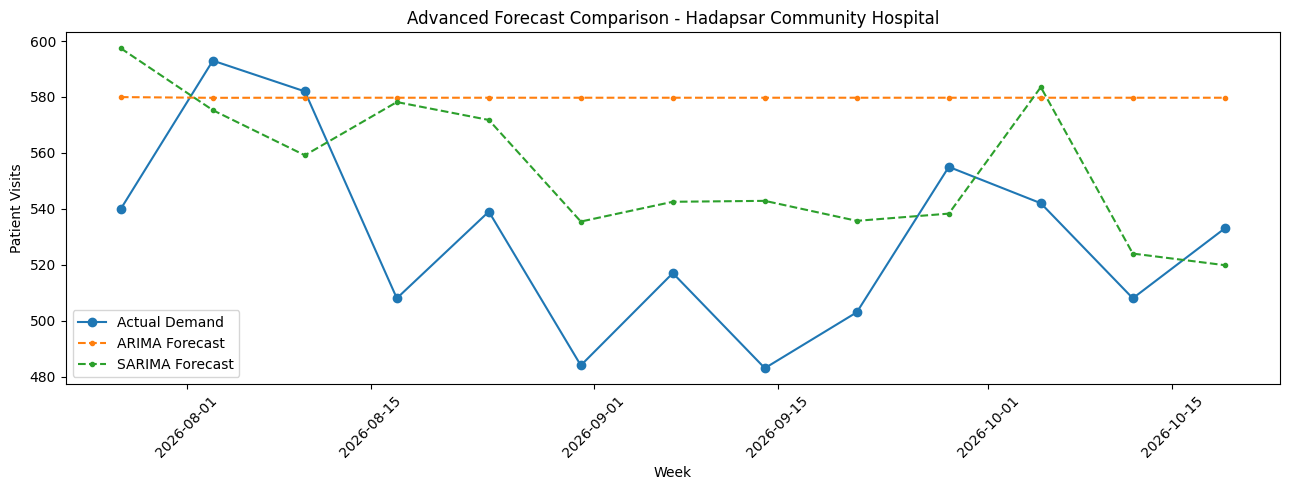

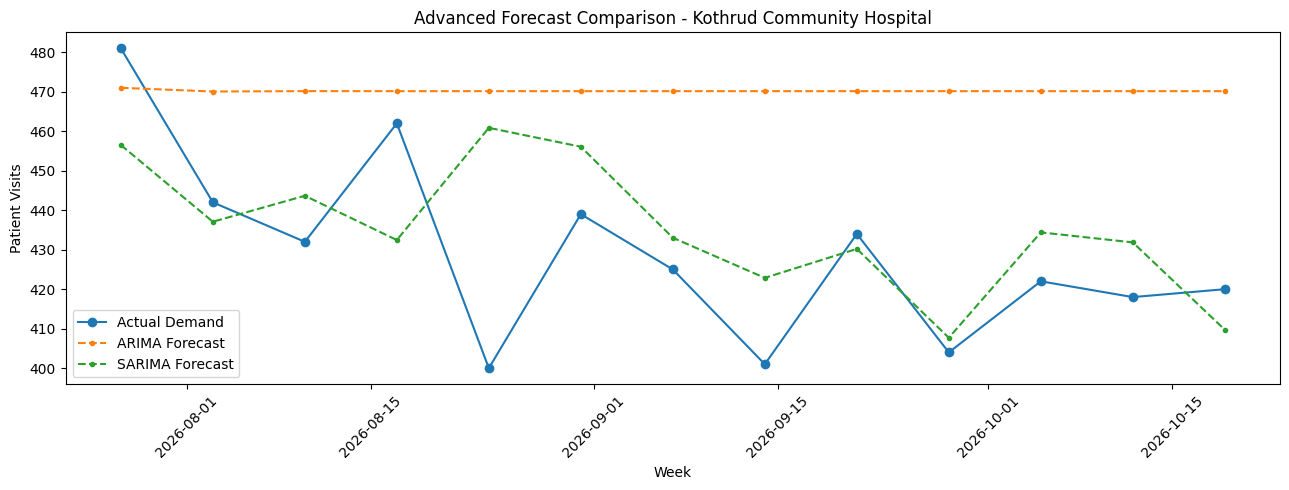

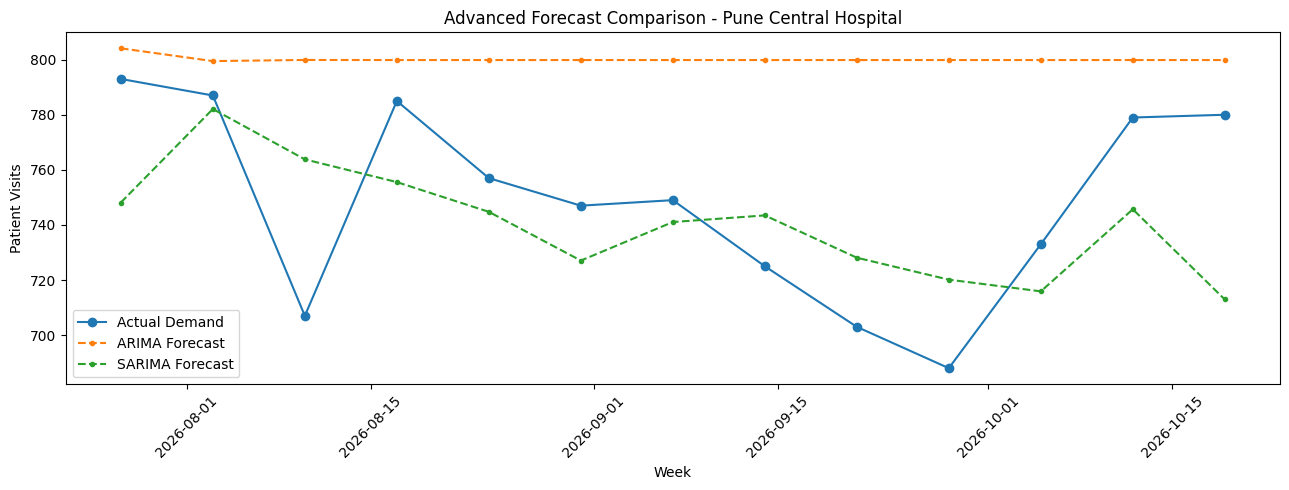

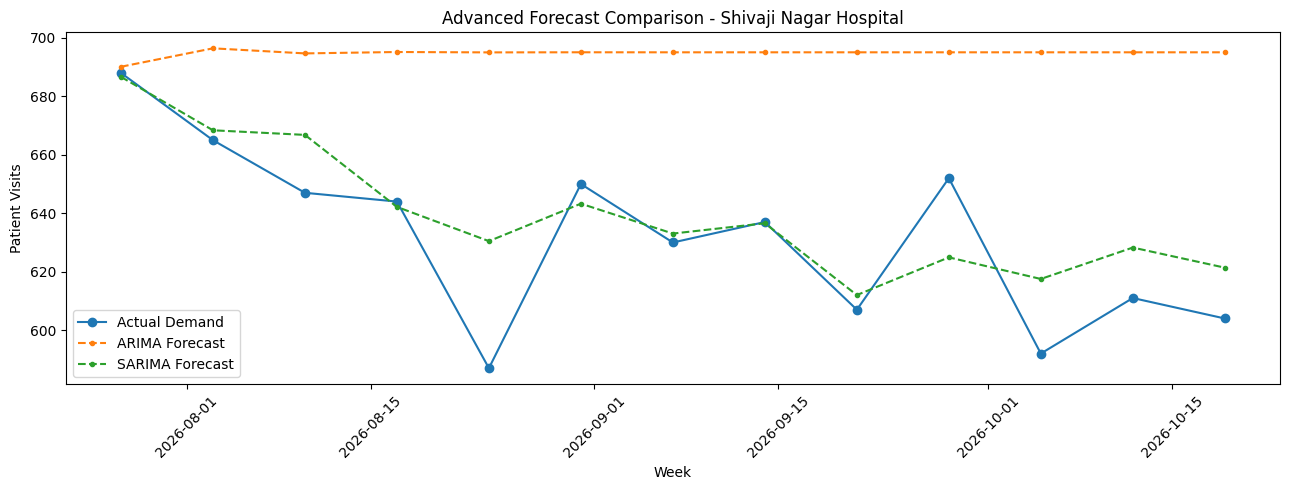

In [47]:
for hospital in sorted(weekly_demand["hospital"].unique()):

    plot_data = advanced_predictions[
        advanced_predictions["hospital"] == hospital
    ]

    if plot_data.empty:
        continue

    plt.figure(figsize=(13, 5))

    actual_data = (
        plot_data[plot_data["model"] == "ARIMA"]
        .sort_values("week_start")
    )

    if actual_data.empty:
        actual_data = (
            plot_data[plot_data["model"] == "SARIMA"]
            .sort_values("week_start")
        )

    plt.plot(
        actual_data["week_start"],
        actual_data["actual"],
        marker="o",
        label="Actual Demand"
    )

    for model_name in ["ARIMA", "SARIMA"]:

        model_data = (
            plot_data[plot_data["model"] == model_name]
            .sort_values("week_start")
        )

        if not model_data.empty:
            plt.plot(
                model_data["week_start"],
                model_data["forecast"],
                linestyle="--",
                marker=".",
                label=f"{model_name} Forecast"
            )

    plt.title(f"Advanced Forecast Comparison - {hospital}")
    plt.xlabel("Week")
    plt.ylabel("Patient Visits")
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [48]:
advanced_metrics.to_csv(
    "data/processed/advanced_model_metrics.csv",
    index=False
)

advanced_predictions.to_csv(
    "data/processed/advanced_model_predictions.csv",
    index=False
)

print("Advanced model results saved successfully!")

Advanced model results saved successfully!


# PHASE 8 – PROPHET FORECASTING AND PREDICTION INTERVALS

In [49]:
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

print("Prophet libraries imported successfully!")

Prophet libraries imported successfully!


In [50]:
prophet_metrics = []
prophet_predictions = []

for hospital in sorted(weekly_demand["hospital"].unique()):

    hospital_data = (
        weekly_demand[
            weekly_demand["hospital"] == hospital
        ]
        .sort_values("week_start")
        .reset_index(drop=True)
    )

    train = hospital_data.iloc[:-13].copy()
    test = hospital_data.iloc[-13:].copy()

    prophet_train = train[["week_start", "total_visits"]].copy()
    prophet_train.columns = ["ds", "y"]

    prophet_train["ds"] = pd.to_datetime(prophet_train["ds"])

    model = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=False,
        daily_seasonality=False,
        interval_width=0.95,
        seasonality_mode="additive"
    )

    try:
        model.fit(prophet_train)

        future = pd.DataFrame({
            "ds": pd.to_datetime(test["week_start"])
        })

        forecast = model.predict(future)

        actual = test["total_visits"].values
        predicted = np.maximum(forecast["yhat"].values, 0)

        lower = np.maximum(forecast["yhat_lower"].values, 0)
        upper = np.maximum(forecast["yhat_upper"].values, 0)

        mae = mean_absolute_error(actual, predicted)

        rmse = np.sqrt(
            mean_squared_error(actual, predicted)
        )

        mape = np.mean(
            np.abs((actual - predicted) / actual)
        ) * 100

        coverage = np.mean(
            (actual >= lower) & (actual <= upper)
        ) * 100

        prophet_metrics.append({
            "hospital": hospital,
            "model": "Prophet",
            "MAE": mae,
            "RMSE": rmse,
            "MAPE": mape,
            "95%_interval_coverage": coverage,
            "status": "Success"
        })

        for i in range(len(test)):
            prophet_predictions.append({
                "hospital": hospital,
                "week_start": test["week_start"].iloc[i],
                "actual": actual[i],
                "forecast": predicted[i],
                "lower_95": lower[i],
                "upper_95": upper[i]
            })

        print(hospital, "- Prophet completed successfully")

    except Exception as e:
        print(hospital, "- Prophet failed:", str(e))

prophet_metrics = pd.DataFrame(prophet_metrics)
prophet_predictions = pd.DataFrame(prophet_predictions)

print("\nProphet forecasting completed!")
display(prophet_metrics.round(2))

09:05:17 - cmdstanpy - INFO - Chain [1] start processing
09:05:17 - cmdstanpy - INFO - Chain [1] done processing
Hadapsar Community Hospital - Prophet completed successfully
09:05:17 - cmdstanpy - INFO - Chain [1] start processing
09:05:17 - cmdstanpy - INFO - Chain [1] done processing
09:05:17 - cmdstanpy - INFO - Chain [1] start processing
09:05:17 - cmdstanpy - INFO - Chain [1] done processing
09:05:18 - cmdstanpy - INFO - Chain [1] start processing
Kothrud Community Hospital - Prophet completed successfully
Pune Central Hospital - Prophet completed successfully
09:05:18 - cmdstanpy - INFO - Chain [1] done processing
Shivaji Nagar Hospital - Prophet completed successfully

Prophet forecasting completed!


,hospital,model,MAE,RMSE,MAPE,95%_interval_coverage,status
0,Hadapsar Community Hospital,Prophet,23.13,27.86,4.43,92.31,Success
1,Kothrud Community Hospital,Prophet,16.68,20.63,3.86,100.00,Success
2,Pune Central Hospital,Prophet,25.17,33.54,3.45,92.31,Success
3,Shivaji Nagar Hospital,Prophet,14.81,20.21,2.39,100.00,Success


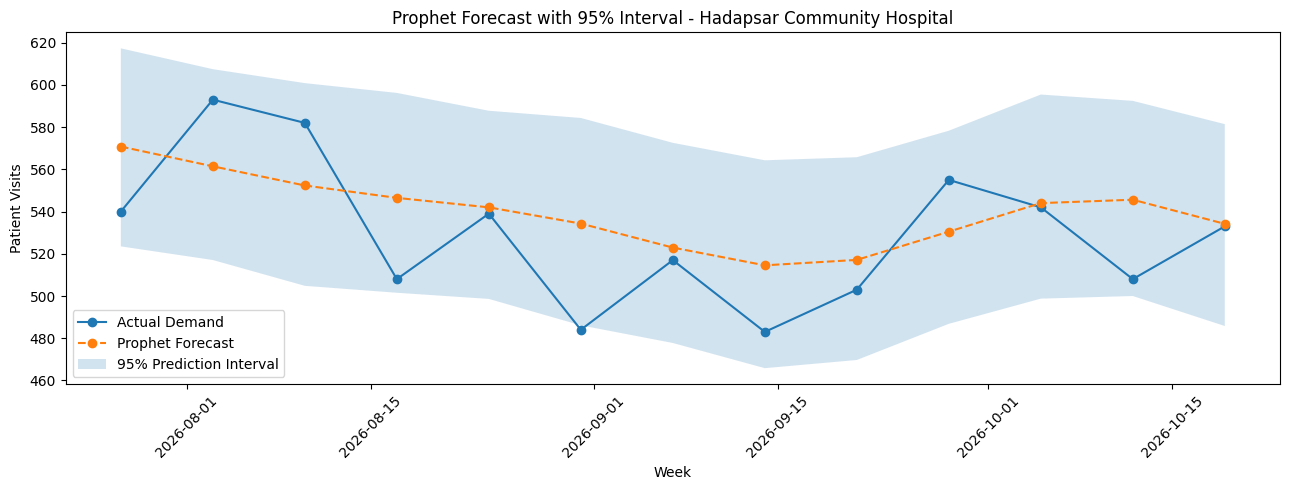

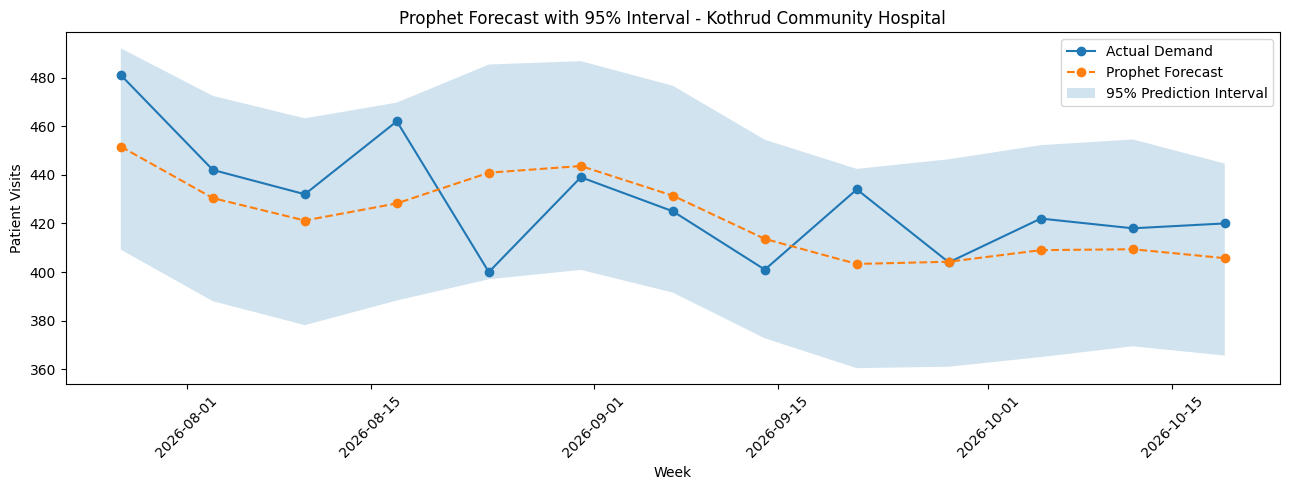

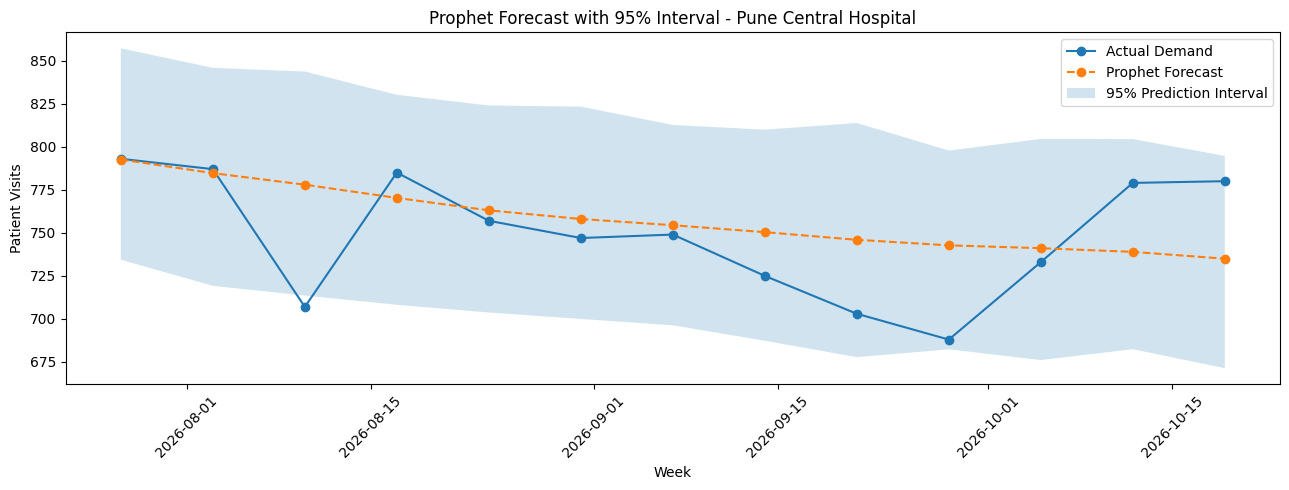

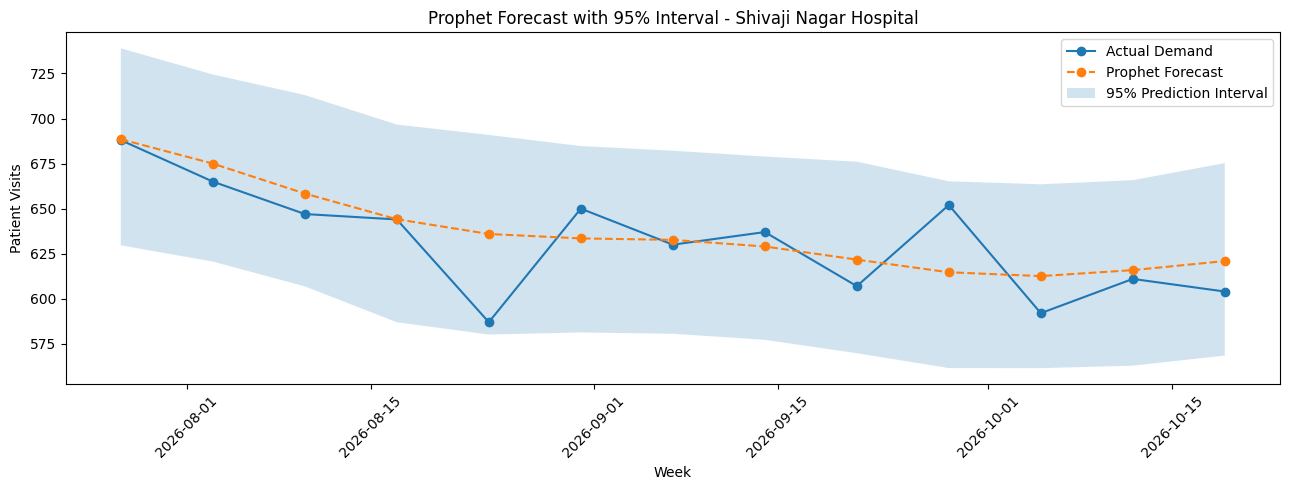

In [51]:
for hospital in sorted(prophet_predictions["hospital"].unique()):

    plot_data = (
        prophet_predictions[
            prophet_predictions["hospital"] == hospital
        ]
        .sort_values("week_start")
    )

    plt.figure(figsize=(13, 5))

    plt.plot(
        plot_data["week_start"],
        plot_data["actual"],
        marker="o",
        label="Actual Demand"
    )

    plt.plot(
        plot_data["week_start"],
        plot_data["forecast"],
        linestyle="--",
        marker="o",
        label="Prophet Forecast"
    )

    plt.fill_between(
        plot_data["week_start"],
        plot_data["lower_95"],
        plot_data["upper_95"],
        alpha=0.2,
        label="95% Prediction Interval"
    )

    plt.title(f"Prophet Forecast with 95% Interval - {hospital}")
    plt.xlabel("Week")
    plt.ylabel("Patient Visits")
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [52]:
all_model_metrics = pd.concat(
    [
        baseline_metrics[["hospital", "model", "MAE", "RMSE", "MAPE"]],
        advanced_metrics[
            advanced_metrics["status"] == "Success"
        ][["hospital", "model", "MAE", "RMSE", "MAPE"]],
        prophet_metrics[
            prophet_metrics["status"] == "Success"
        ][["hospital", "model", "MAE", "RMSE", "MAPE"]]
    ],
    ignore_index=True
)

print("Complete model performance comparison:")
display(
    all_model_metrics
    .groupby("model")[["MAE", "RMSE", "MAPE"]]
    .mean()
    .sort_values("MAE")
    .round(2)
)

Complete model performance comparison:


,MAE,RMSE,MAPE
model,,,
Prophet,19.95,25.56,3.53
SARIMA,23.50,28.56,4.19
Seasonal Naive,39.13,46.56,6.59
Naive,49.33,54.57,8.90
ARIMA,52.32,59.34,9.42


In [53]:
prophet_metrics.to_csv(
    "data/processed/prophet_model_metrics.csv",
    index=False
)

prophet_predictions.to_csv(
    "data/processed/prophet_predictions.csv",
    index=False
)

all_model_metrics.to_csv(
    "data/processed/all_model_comparison.csv",
    index=False
)

print("Phase 8 results saved successfully!")
print("1. prophet_model_metrics.csv")
print("2. prophet_predictions.csv")
print("3. all_model_comparison.csv")

Phase 8 results saved successfully!
1. prophet_model_metrics.csv
2. prophet_predictions.csv
3. all_model_comparison.csv


# PHASE 9 – FINAL HOSPITAL DEMAND FORECASTING AND RESOURCE PLANNING

In [54]:
from prophet import Prophet
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

forecast_results = []

forecast_targets = [
    "total_visits",
    "opd_visits",
    "admissions"
]

hospitals = sorted(weekly_demand["hospital"].unique())

for hospital in hospitals:

    hospital_data = (
        weekly_demand[
            weekly_demand["hospital"] == hospital
        ]
        .sort_values("week_start")
        .copy()
    )

    for target in forecast_targets:

        train_data = hospital_data[
            ["week_start", target]
        ].copy()

        train_data.columns = ["ds", "y"]

        train_data["ds"] = pd.to_datetime(
            train_data["ds"]
        )

        model = Prophet(
            yearly_seasonality=True,
            weekly_seasonality=False,
            daily_seasonality=False,
            interval_width=0.95,
            seasonality_mode="additive"
        )

        model.fit(train_data)

        future = model.make_future_dataframe(
            periods=13,
            freq="W-MON",
            include_history=False
        )

        forecast = model.predict(future)

        for i in range(13):

            forecast_results.append({
                "hospital": hospital,
                "week_start": forecast["ds"].iloc[i],
                "forecast_type": target,
                "forecast": max(
                    0, forecast["yhat"].iloc[i]
                ),
                "lower_95": max(
                    0, forecast["yhat_lower"].iloc[i]
                ),
                "upper_95": max(
                    0, forecast["yhat_upper"].iloc[i]
                )
            })

        print(hospital, "-", target, "forecast completed")

final_forecasts = pd.DataFrame(forecast_results)

print("\nFinal 13-week forecasting completed!")
display(final_forecasts.head(15).round(2))

09:05:19 - cmdstanpy - INFO - Chain [1] start processing
09:05:19 - cmdstanpy - INFO - Chain [1] done processing
09:05:19 - cmdstanpy - INFO - Chain [1] start processing
09:05:19 - cmdstanpy - INFO - Chain [1] done processing
09:05:19 - cmdstanpy - INFO - Chain [1] start processing
09:05:19 - cmdstanpy - INFO - Chain [1] done processing
09:05:19 - cmdstanpy - INFO - Chain [1] start processing
09:05:19 - cmdstanpy - INFO - Chain [1] done processing
Hadapsar Community Hospital - total_visits forecast completed
Hadapsar Community Hospital - opd_visits forecast completed
Hadapsar Community Hospital - admissions forecast completed
Kothrud Community Hospital - total_visits forecast completed
09:05:19 - cmdstanpy - INFO - Chain [1] start processing
09:05:19 - cmdstanpy - INFO - Chain [1] done processing
09:05:19 - cmdstanpy - INFO - Chain [1] start processing
09:05:19 - cmdstanpy - INFO - Chain [1] done processing
Kothrud Community Hospital - opd_visits forecast completed
09:05:20 - cmdstanpy

,hospital,week_start,forecast_type,forecast,lower_95,upper_95
0,Hadapsar Community Hospital,2026-10-26,total_visits,517.87,470.59,562.22
1,Hadapsar Community Hospital,2026-11-02,total_visits,520.64,474.45,563.89
2,Hadapsar Community Hospital,2026-11-09,total_visits,538.32,491.12,584.26
3,Hadapsar Community Hospital,2026-11-16,total_visits,560.13,512.55,608.04
4,Hadapsar Community Hospital,2026-11-23,total_visits,573.31,525.40,618.09
5,Hadapsar Community Hospital,2026-11-30,total_visits,575.40,526.82,623.13
6,Hadapsar Community Hospital,2026-12-07,total_visits,575.84,528.66,623.90
7,Hadapsar Community Hospital,2026-12-14,total_visits,585.80,537.82,632.09
8,Hadapsar Community Hospital,2026-12-21,total_visits,606.87,559.08,651.44
9,Hadapsar Community Hospital,2026-12-28,total_visits,630.08,584.21,677.52


In [55]:
admission_history = df_clean[
    df_clean["visit_type"] == "Admission"
].copy()

average_los = (
    admission_history
    .groupby("hospital")["length_of_stay"]
    .mean()
    .rename("average_los_days")
    .reset_index()
)

bed_planning = (
    final_forecasts[
        final_forecasts["forecast_type"] == "admissions"
    ]
    .merge(average_los, on="hospital", how="left")
    .copy()
)

bed_planning["estimated_average_beds"] = (
    bed_planning["forecast"] *
    bed_planning["average_los_days"] / 7
)

bed_planning["estimated_beds_lower"] = (
    bed_planning["lower_95"] *
    bed_planning["average_los_days"] / 7
)

bed_planning["estimated_beds_upper"] = (
    bed_planning["upper_95"] *
    bed_planning["average_los_days"] / 7
)

print("Estimated bed demand:")
display(bed_planning.round(2).head(15))

Estimated bed demand:


,hospital,week_start,forecast_type,forecast,lower_95,upper_95,average_los_days,estimated_average_beds,estimated_beds_lower,estimated_beds_upper
0,Hadapsar Community Hospital,2026-10-26,admissions,61.74,45.95,75.89,7.51,66.22,49.28,81.40
1,Hadapsar Community Hospital,2026-11-02,admissions,60.32,46.35,75.89,7.51,64.70,49.72,81.40
2,Hadapsar Community Hospital,2026-11-09,admissions,60.27,45.57,74.42,7.51,64.64,48.88,79.83
3,Hadapsar Community Hospital,2026-11-16,admissions,62.27,47.83,78.03,7.51,66.79,51.30,83.69
4,Hadapsar Community Hospital,2026-11-23,admissions,65.74,51.28,80.01,7.51,70.52,55.00,85.82
5,Hadapsar Community Hospital,2026-11-30,admissions,68.81,52.95,84.16,7.51,73.80,56.79,90.27
6,Hadapsar Community Hospital,2026-12-07,admissions,70.06,56.47,84.42,7.51,75.14,60.57,90.55
7,Hadapsar Community Hospital,2026-12-14,admissions,70.30,55.81,85.37,7.51,75.40,59.86,91.57
8,Hadapsar Community Hospital,2026-12-21,admissions,71.90,56.74,86.48,7.51,77.12,60.86,92.76
9,Hadapsar Community Hospital,2026-12-28,admissions,76.04,60.74,91.41,7.51,81.56,65.16,98.05


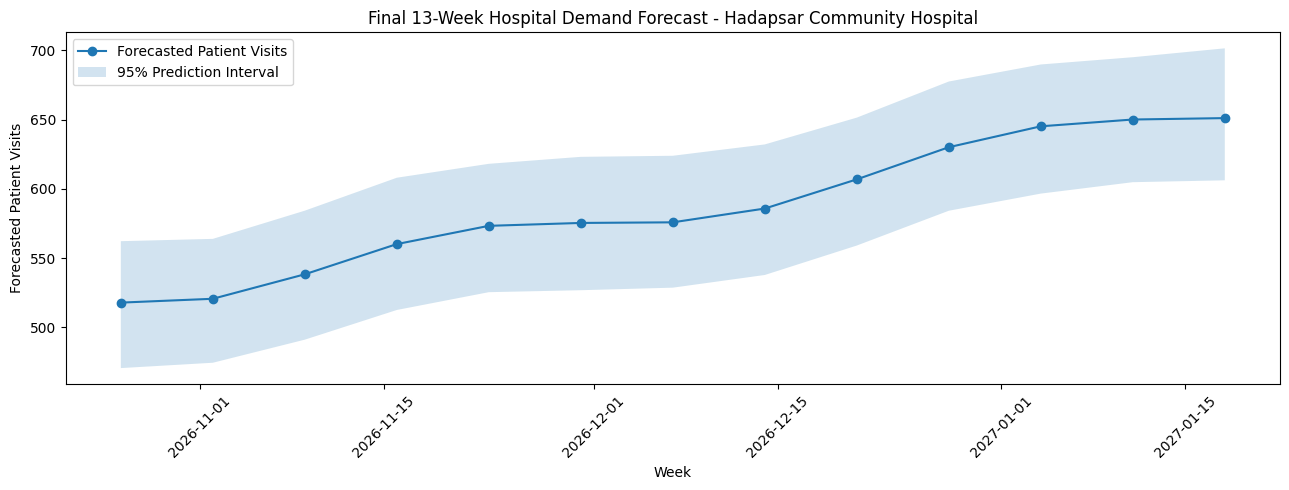

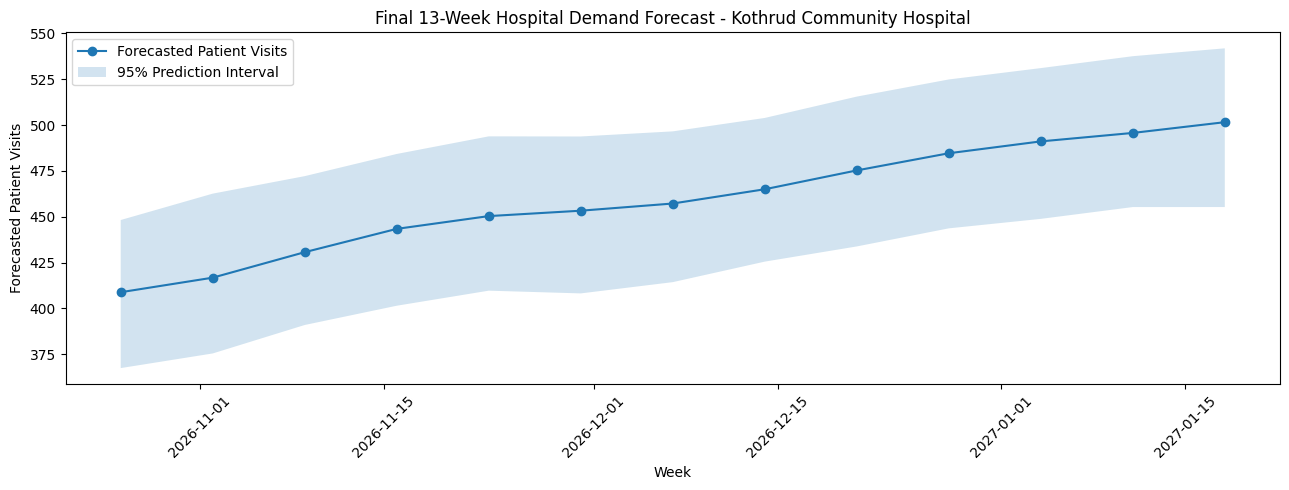

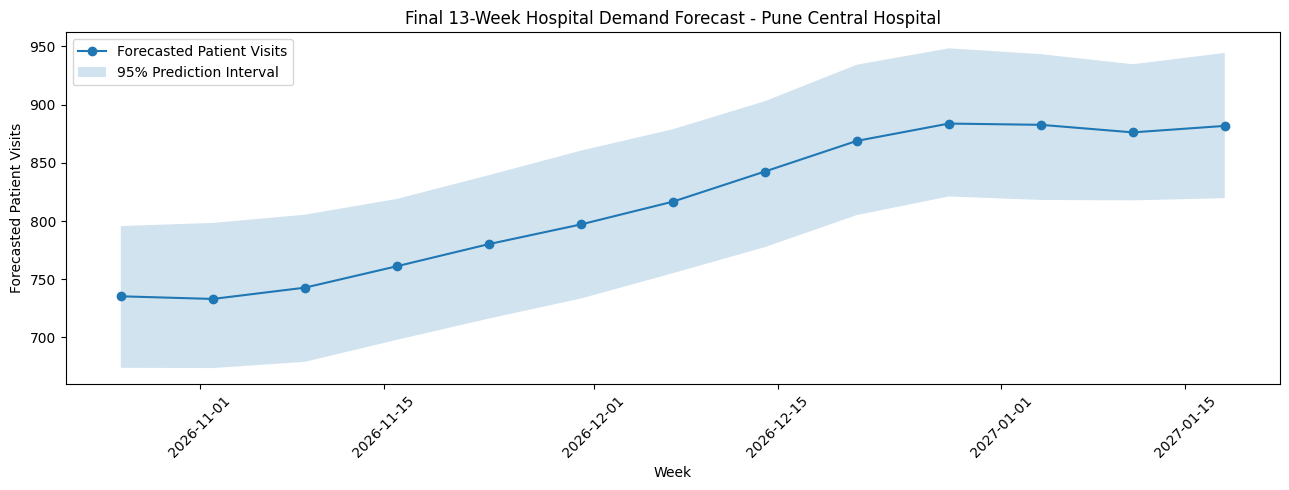

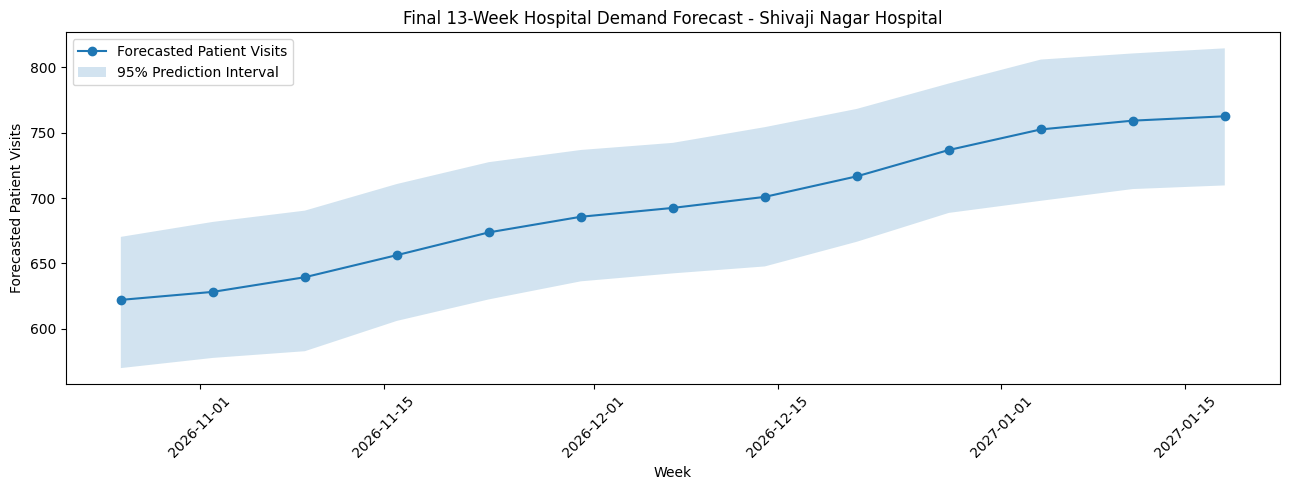

In [56]:
for hospital in hospitals:

    hospital_forecast = final_forecasts[
        (final_forecasts["hospital"] == hospital) &
        (final_forecasts["forecast_type"] == "total_visits")
    ].sort_values("week_start")

    plt.figure(figsize=(13, 5))

    plt.plot(
        hospital_forecast["week_start"],
        hospital_forecast["forecast"],
        marker="o",
        label="Forecasted Patient Visits"
    )

    plt.fill_between(
        hospital_forecast["week_start"],
        hospital_forecast["lower_95"],
        hospital_forecast["upper_95"],
        alpha=0.2,
        label="95% Prediction Interval"
    )

    plt.title(f"Final 13-Week Hospital Demand Forecast - {hospital}")
    plt.xlabel("Week")
    plt.ylabel("Forecasted Patient Visits")
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [57]:
final_forecasts.to_csv(
    "data/forecasts/final_13_week_hospital_forecast.csv",
    index=False
)

bed_planning.to_csv(
    "data/forecasts/hospital_bed_planning.csv",
    index=False
)

print("Phase 9 results saved successfully!")
print("1. final_13_week_hospital_forecast.csv")
print("2. hospital_bed_planning.csv")

Phase 9 results saved successfully!
1. final_13_week_hospital_forecast.csv
2. hospital_bed_planning.csv


# \# PHASE 10: FINAL FORECAST VALIDATION

In [58]:

forecast_file = "data/forecasts/final_13_week_hospital_forecast.csv"
bed_file = "data/forecasts/hospital_bed_planning.csv"

final_forecast = pd.read_csv(forecast_file)
bed_planning = pd.read_csv(bed_file)

print("FINAL FORECAST VALIDATION")
print("-" * 50)

print("Total forecast records:", len(final_forecast))
print("Hospitals:", final_forecast["hospital"].nunique())
print("Forecast types:", final_forecast["forecast_type"].unique())

print("\nForecast records by hospital:")
display(
    final_forecast.groupby(
        ["hospital", "forecast_type"]
    ).size().reset_index(name="weeks")
)

print("\nChecking prediction intervals:")
print(
    "Invalid intervals:",
    (
        (final_forecast["lower_95"] > final_forecast["forecast"]) |
        (final_forecast["forecast"] > final_forecast["upper_95"])
    ).sum()
)

print("\nChecking missing values:")
print(final_forecast.isnull().sum())

print("\nBED PLANNING SUMMARY:")
display(
    bed_planning.groupby("hospital")[
        ["estimated_average_beds",
         "estimated_beds_lower",
         "estimated_beds_upper"]
    ].mean().round(2)
)

print("\nPhase 10 validation completed!")

FINAL FORECAST VALIDATION
--------------------------------------------------
Total forecast records: 156
Hospitals: 4
Forecast types: ['total_visits' 'opd_visits' 'admissions']

Forecast records by hospital:


,hospital,forecast_type,weeks
0,Hadapsar Community Hospital,admissions,13
1,Hadapsar Community Hospital,opd_visits,13
2,Hadapsar Community Hospital,total_visits,13
3,Kothrud Community Hospital,admissions,13
4,Kothrud Community Hospital,opd_visits,13
5,Kothrud Community Hospital,total_visits,13
6,Pune Central Hospital,admissions,13
7,Pune Central Hospital,opd_visits,13
8,Pune Central Hospital,total_visits,13
9,Shivaji Nagar Hospital,admissions,13



Checking prediction intervals:
Invalid intervals: 0

Checking missing values:
hospital         0
week_start       0
forecast_type    0
forecast         0
lower_95         0
upper_95         0
dtype: int64

BED PLANNING SUMMARY:


,estimated_average_beds,estimated_beds_lower,estimated_beds_upper
hospital,,,
Hadapsar Community Hospital,75.49,59.73,91.63
Kothrud Community Hospital,60.33,45.81,75.42
Pune Central Hospital,105.72,84.28,126.96
Shivaji Nagar Hospital,91.51,73.30,109.31



Phase 10 validation completed!


#  PHASE 11: BUSINESS INSIGHTS AND RECOMMENDATIONS

In [59]:
# PHASE 11: BUSINESS INSIGHTS AND RECOMMENDATIONS

print("HOSPITAL-WISE FORECAST SUMMARY")
print("=" * 60)

# Summarize weekly demand for each hospital and forecast type
demand_summary = (
    final_forecast
    .groupby(["hospital", "forecast_type"])
    .agg(
        average_forecast=("forecast", "mean"),
        minimum_forecast=("forecast", "min"),
        maximum_forecast=("forecast", "max"),
        average_lower_95=("lower_95", "mean"),
        average_upper_95=("upper_95", "mean")
    )
    .round(2)
    .reset_index()
)

display(demand_summary)

print("\nHOSPITAL BED PLANNING SUMMARY")
print("=" * 60)

bed_summary = (
    bed_planning
    .groupby("hospital")
    .agg(
        average_beds=("estimated_average_beds", "mean"),
        peak_average_beds=("estimated_average_beds", "max"),
        average_lower_beds=("estimated_beds_lower", "mean"),
        peak_upper_beds=("estimated_beds_upper", "max")
    )
    .round(2)
    .reset_index()
)

display(bed_summary)

# Save final summaries
demand_summary.to_csv(
    "data/forecasts/hospital_demand_summary.csv",
    index=False
)

bed_summary.to_csv(
    "data/forecasts/hospital_bed_summary.csv",
    index=False
)

print("\nPhase 11 completed successfully!")
print("1. hospital_demand_summary.csv")
print("2. hospital_bed_summary.csv")

HOSPITAL-WISE FORECAST SUMMARY


,hospital,forecast_type,average_forecast,minimum_forecast,maximum_forecast,average_lower_95,average_upper_95
0,Hadapsar Community Hospital,admissions,70.38,60.27,83.67,55.69,85.43
1,Hadapsar Community Hospital,opd_visits,515.85,455.50,567.60,470.23,561.31
2,Hadapsar Community Hospital,total_visits,586.97,517.87,651.09,539.87,633.15
3,Kothrud Community Hospital,admissions,56.11,48.38,65.07,42.61,70.15
4,Kothrud Community Hospital,opd_visits,402.62,359.76,441.83,365.15,440.19
5,Kothrud Community Hospital,total_visits,459.52,408.87,501.55,417.71,500.45
6,Pune Central Hospital,admissions,98.83,92.99,106.93,78.79,118.68
7,Pune Central Hospital,opd_visits,714.17,636.27,778.62,661.07,767.27
8,Pune Central Hospital,total_visits,815.51,733.07,883.70,752.97,877.32
9,Shivaji Nagar Hospital,admissions,85.22,70.31,96.69,68.26,101.80



HOSPITAL BED PLANNING SUMMARY


,hospital,average_beds,peak_average_beds,average_lower_beds,peak_upper_beds
0,Hadapsar Community Hospital,75.49,89.74,59.73,106.67
1,Kothrud Community Hospital,60.33,69.97,45.81,84.12
2,Pune Central Hospital,105.72,114.38,84.28,136.45
3,Shivaji Nagar Hospital,91.51,103.83,73.30,122.16



Phase 11 completed successfully!
1. hospital_demand_summary.csv
2. hospital_bed_summary.csv


# Hospital Demand Forecasting Using Time-Series Analysis

## 1. Executive Summary
This project focuses on forecasting hospital demand across four hospitals in Pune using historical patient records and time-series forecasting techniques.

## 2. Problem Statement
Hospitals need reliable demand estimates to plan staffing, patient services, and bed availability. This project develops a forecasting approach to support these operational decisions.

## 3. Project Objectives
- Forecast hospital demand for the next 13 weeks.
- Analyze OPD visits and hospital admissions.
- Compare multiple forecasting models.
- Evaluate model performance using MAE, RMSE, and MAPE.
- Estimate bed requirements using admission forecasts and average length of stay.
- Provide actionable recommendations for hospital management.

## 4. Dataset Description
Describe the dataset, its columns, date range, four fictional hospitals, and data-generation method. Clearly state that the dataset is synthetic and does not contain actual hospital patient records.

## 5. Data Cleaning and Preprocessing
Explain missing-value treatment, age correction, duplicate removal, date validation, outlier identification, and weekly aggregation.

## 6. Exploratory Data Analysis
Include hospital-wise demand trends, seasonal decomposition, and stationarity testing.

## 7. Forecasting Methodology
Explain the training and testing split, baseline models, ARIMA, SARIMA, and Prophet.

## 8. Model Evaluation
Present MAE, RMSE, and MAPE results. Explain why Prophet was selected as the final forecasting model based on the evaluation results.

## 9. Final 13-Week Forecast
Include the forecast tables and visualizations for total visits, OPD visits, and admissions across all four hospitals.

## 10. Hospital Bed Planning
Explain how admission forecasts and average length of stay were used to estimate average occupied beds and planning intervals.

## 11. Business Recommendations
Discuss staffing preparation, bed-capacity planning, OPD resource allocation, and regular forecast monitoring.

## 12. Limitations
Explain the limitations of synthetic data, model assumptions, prediction uncertainty, and the need for validation using real hospital data.

## 13. Conclusion
Summarize the project's results and explain how forecasting can support hospital operational planning.

## 14. Future Enhancements
- Integrate real hospital datasets.
- Include department-wise forecasting.
- Develop an interactive Power BI dashboard.
- Automate weekly forecast updates.
- Explore machine-learning models for improved predictions.

In [60]:
# Final project performance summary

print("HOSPITAL DEMAND FORECASTING - FINAL RESULTS")
print("=" * 55)

print("\n1. MODEL PERFORMANCE")
display(
    all_model_metrics
    .groupby("model")[["MAE", "RMSE", "MAPE"]]
    .mean()
    .sort_values("MAE")
    .round(2)
)

print("\n2. BEST MODEL")
print("Selected model: Prophet")
print("Average MAE: 19.95")
print("Average RMSE: 25.56")
print("Average MAPE: 3.53%")

print("\n3. FORECAST COVERAGE")
display(
    final_forecast.groupby(
        ["hospital", "forecast_type"]
    ).size().reset_index(name="forecast_weeks")
)

print("\n4. BED PLANNING")
display(bed_summary.round(2))

print("\nFinal project results generated successfully!")

HOSPITAL DEMAND FORECASTING - FINAL RESULTS

1. MODEL PERFORMANCE


,MAE,RMSE,MAPE
model,,,
Prophet,19.95,25.56,3.53
SARIMA,23.50,28.56,4.19
Seasonal Naive,39.13,46.56,6.59
Naive,49.33,54.57,8.90
ARIMA,52.32,59.34,9.42



2. BEST MODEL
Selected model: Prophet
Average MAE: 19.95
Average RMSE: 25.56
Average MAPE: 3.53%

3. FORECAST COVERAGE


,hospital,forecast_type,forecast_weeks
0,Hadapsar Community Hospital,admissions,13
1,Hadapsar Community Hospital,opd_visits,13
2,Hadapsar Community Hospital,total_visits,13
3,Kothrud Community Hospital,admissions,13
4,Kothrud Community Hospital,opd_visits,13
5,Kothrud Community Hospital,total_visits,13
6,Pune Central Hospital,admissions,13
7,Pune Central Hospital,opd_visits,13
8,Pune Central Hospital,total_visits,13
9,Shivaji Nagar Hospital,admissions,13



4. BED PLANNING


,hospital,average_beds,peak_average_beds,average_lower_beds,peak_upper_beds
0,Hadapsar Community Hospital,75.49,89.74,59.73,106.67
1,Kothrud Community Hospital,60.33,69.97,45.81,84.12
2,Pune Central Hospital,105.72,114.38,84.28,136.45
3,Shivaji Nagar Hospital,91.51,103.83,73.30,122.16



Final project results generated successfully!


## 8. Model Evaluation and Comparison

The performance of five forecasting models was evaluated using
Mean Absolute Error (MAE), Root Mean Squared Error (RMSE),
and Mean Absolute Percentage Error (MAPE).
Lower values indicate better forecasting performance.

In [61]:
# Model comparison table

model_comparison = (
    all_model_metrics
    .groupby("model")[["MAE", "RMSE", "MAPE"]]
    .mean()
    .sort_values("MAE")
    .round(2)
)

display(model_comparison)

,MAE,RMSE,MAPE
model,,,
Prophet,19.95,25.56,3.53
SARIMA,23.50,28.56,4.19
Seasonal Naive,39.13,46.56,6.59
Naive,49.33,54.57,8.90
ARIMA,52.32,59.34,9.42


## 9. Forecast Coverage

The selected Prophet model was used to generate 13-week forecasts
for four hospitals across three demand categories:
total visits, OPD visits, and admissions.

In [62]:
# Forecast coverage table

forecast_coverage = (
    final_forecast
    .groupby(["hospital", "forecast_type"])
    .size()
    .reset_index(name="forecast_weeks")
)

display(forecast_coverage)

,hospital,forecast_type,forecast_weeks
0,Hadapsar Community Hospital,admissions,13
1,Hadapsar Community Hospital,opd_visits,13
2,Hadapsar Community Hospital,total_visits,13
3,Kothrud Community Hospital,admissions,13
4,Kothrud Community Hospital,opd_visits,13
5,Kothrud Community Hospital,total_visits,13
6,Pune Central Hospital,admissions,13
7,Pune Central Hospital,opd_visits,13
8,Pune Central Hospital,total_visits,13
9,Shivaji Nagar Hospital,admissions,13


## 10. Hospital Bed Planning

Bed requirements were estimated using forecasted hospital admissions
and the historical average length of stay (LOS).

The estimates provide an illustrative planning reference for
understanding potential bed demand.

In [63]:
# Hospital bed-planning summary

display(bed_summary.round(2))

,hospital,average_beds,peak_average_beds,average_lower_beds,peak_upper_beds
0,Hadapsar Community Hospital,75.49,89.74,59.73,106.67
1,Kothrud Community Hospital,60.33,69.97,45.81,84.12
2,Pune Central Hospital,105.72,114.38,84.28,136.45
3,Shivaji Nagar Hospital,91.51,103.83,73.30,122.16


## 12. Business Recommendations

Based on the forecasting results, the following recommendations can support hospital resource planning:

1. **Staff planning:** Hospitals can use weekly demand forecasts to plan staffing levels according to expected patient visits.
2. **Bed management:** Estimated bed occupancy can help hospital administrators plan bed availability and reduce resource shortages.
3. **Department planning:** Historical demand patterns can help identify departments that may require additional staff, equipment, or supplies.
4. **Resource allocation:** Hospitals can use demand estimates to plan medicines, laboratory supplies, and other essential resources.
5. **Regular monitoring:** Forecasts should be compared with actual patient demand and updated regularly to improve planning.

## 13. Project Limitations

1. The dataset used in this project is synthetically generated and does not represent actual hospital patient records.
2. The forecasting results are based on historical patterns in the generated dataset.
3. The project uses a limited number of hospitals and departments.
4. Forecasting performance may change when applied to real-world hospital data.
5. Bed requirements are approximate estimates based on admissions and historical average length of stay. They do not account for every operational factor.
6. The evaluation uses a holdout test period; additional rolling-origin validation would provide stronger evidence of model reliability.

## 14. Conclusion

The Hospital Demand Forecasting project demonstrates how data analysis and time-series forecasting can be used to understand and estimate future hospital demand.

The project involved synthetic data generation, data cleaning, exploratory data analysis, weekly demand aggregation, time-series analysis, and the evaluation of multiple forecasting models.

Among the five evaluated models, Prophet achieved the best average performance, with an MAE of 19.95, RMSE of 25.56, and MAPE of 3.53%.

The selected model was used to generate 13-week forecasts for four hospitals across total visits, OPD visits, and admissions. Estimated bed-planning summaries were also generated to demonstrate how forecasts may support resource planning.

Overall, this project provided practical experience in data preprocessing, exploratory analysis, forecasting, model evaluation, and communicating analytical results.

**Note:** All findings and forecasts are illustrative because the project uses synthetic data. Real hospital data and operational validation would be required before using the results for actual decisions.

## 15. Future Enhancements

- Integrate real hospital data with appropriate privacy and security controls.
- Perform rolling-origin time-series cross-validation.
- Explore additional forecasting models and compare their performance.
- Develop a Power BI dashboard for interactive hospital demand monitoring.
- Include department-level forecasts and more detailed resource-planning factors.
- Build an automated forecasting pipeline that updates predictions as new data becomes available.

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=02ab41a2-1968-4751-99ca-293b6380097e' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>